In [1]:
import pandas as pd
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns
import os
from os import stat
from scipy.stats import kruskal
from scipy.stats import mannwhitneyu
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report
from IPython.display import display
import textwrap
import numpy as np
from google.colab import drive
from sklearn.ensemble import RandomForestClassifier
import joblib

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
path_data = "/content/drive/MyDrive/Dados TCC/dadosRespostas.csv"
new_path = "/content/drive/MyDrive/Dados TCC/dadosRespostasLimpo.csv"
model_path = "/content/drive/MyDrive/Dados TCC/Meus_Modelos_Salvos/"
os.makedirs(model_path, exist_ok=True)
df = pd.read_csv(path_data)


df = df.drop(df.columns[0], axis=1)

df.columns = df.columns.str.strip()

perguntas_originais = df.columns.tolist()

novos_nomes = [f"Q{i+1}" for i in range(len(perguntas_originais))]
df.columns = novos_nomes
df['Q1'] = df['Q1'].str.replace(r'\D+', '-', regex=True).str.strip('-')

ultima_coluna = df.columns[-1]
df[ultima_coluna] = df[ultima_coluna].astype(str).str.extract(r'^(\d+)')[0]

df.to_csv(new_path, index=False)


In [3]:
dados_limpos = pd.read_csv(new_path)

In [4]:
Qs = ['Q4','Q5','Q6','Q7','Q8','Q9','Q10','Q11','Q12','Q13','Q14', 'Q16', 'Q18']
for Q in Qs:
    print(f'Analisando a media de {Q}')
    print(f'media: {dados_limpos[Q].mean()}')
    print(f'var: {dados_limpos[Q].var()}')
    print(f'std: {dados_limpos[Q].std()}')
    print('----------------------------')


Analisando a media de Q4
media: 2.3278688524590163
var: 2.6850020322449546
std: 1.6385975809346707
----------------------------
Analisando a media de Q5
media: 3.901639344262295
var: 3.4282617531499784
std: 1.8515565757356642
----------------------------
Analisando a media de Q6
media: 2.639344262295082
var: 3.7696789052973805
std: 1.9415660960413839
----------------------------
Analisando a media de Q7
media: 6.10655737704918
var: 1.451361604118684
std: 1.20472470055141
----------------------------
Analisando a media de Q8
media: 3.4344262295081966
var: 4.1320281804633545
std: 2.0327390832232637
----------------------------
Analisando a media de Q9
media: 5.475409836065574
var: 3.0779027232082408
std: 1.754395258545873
----------------------------
Analisando a media de Q10
media: 4.040983606557377
var: 3.659463487332338
std: 1.9129724219999455
----------------------------
Analisando a media de Q11
media: 3.442622950819672
var: 4.182631079799486
std: 2.04514818040148
------------------

In [5]:
#Agrupamento do Autor
area_atuacao = {
    'Tecnologia': 'Exatas e Tecnologia',
    'Tecnologias' :'Exatas e Tecnologia',
    'Desenvolvimento De Sistemas': 'Exatas e Tecnologia',
    'Desenvolvimento De Software': 'Exatas e Tecnologia',
    'Ciência E Tecnologia': 'Exatas e Tecnologia',
    'Desenvolvedor Web': 'Exatas e Tecnologia',
    'Pesquisa Em Tecnologia' : 'Exatas e Tecnologia',
    'Ciência - Microbiologia Molecular E Bioinformática' : 'Exatas e Tecnologia',
    'Meio Ambiente': 'Exatas e Tecnologia',
    'Estudante De Biotecnologia': 'Exatas e Tecnologia',
    'Química': 'Exatas e Tecnologia',
    'Engenharia' : 'Exatas e Tecnologia',

    'Saúde' : 'Saúde e Biológicas',
    'Saude' : 'Saúde e Biológicas',
    'Saúde (Psicóloga).': 'Saúde e Biológicas',
    'Saúde E Ciências Agrárias': 'Saúde e Biológicas',
    'Educação e Saúde': 'Saúde e Biológicas',
    'Educação E Saúde': 'Saúde e Biológicas',
    'Fisioterapia': 'Saúde e Biológicas',
    'Farmacêutica Aposentada': 'Saúde e Biológicas',
    'Nutrição': 'Saúde e Biológicas',
    'Psicologia E Artesanato': 'Saúde e Biológicas',
    'Psicologia' : 'Saúde e Biológicas',

    'Design De Moda': 'Artes e Design',
    'Artes (Fotografia) E Educação': 'Artes e Design',
    'Arte Educação': 'Artes e Design',
    'Artes': 'Artes e Design',
    'Arte': 'Artes e Design',
    'Artista Independente': 'Artes e Design',
    'Artes ': 'Artes e Design',
    'Linguagens E Arte': 'Artes e Design',
    'Artista (Digital, Tatuador E Artesão)': 'Artes e Design',
    'Arquitetura E Urbanismo':'Artes e Design',
    'Arquitetura':'Artes e Design',
    'Marketing': 'Artes e Design',

    'Direito': 'Humanas e Negócios',
    'Advogada (Direito- Humanas)': 'Humanas e Negócios',
    'Jurídica/Compliance': 'Humanas e Negócios',
    'Jurídica': 'Humanas e Negócios',
    'Jurídico': 'Humanas e Negócios',
    'Área Jurídica':'Humanas e Negócios',
    'Administração':'Humanas e Negócios',
    'Administração':'Humanas e Negócios',
    'Adm':'Humanas e Negócios',
    'Analista Fiscal':'Humanas e Negócios',
    'Gestão Pública E Pesquisa Acadêmica':'Humanas e Negócios',
    'Educação E Ciência Social':'Humanas e Negócios',
    'Estudande De Arquitetura E Urbanismo':'Humanas e Negócios',
    'Gestão Pública ':'Humanas e Negócios',
    'Administrativo':'Humanas e Negócios',
    'Construção Civil':'Humanas e Negócios',
    'Auditoria': 'Humanas e Negócios',
    'Gestão De Pessoas': 'Humanas e Negócios',
    'Empresário': 'Humanas e Negócios',
    'Gestão Pública': 'Humanas e Negócios',
    'Setor Financeiro': 'Humanas e Negócios',
    'Humanas': 'Humanas e Negócios',
    'Educação E Pesquisa': 'Humanas e Negócios',


    'Atendimento De Pessoas': 'Serviços e Operacional',
    'Manicure': 'Serviços e Operacional',
    'Cabeleireira': 'Serviços e Operacional',
    'Varejo': 'Serviços e Operacional',
    'Aviação': 'Serviços e Operacional',
    'Militar': 'Serviços e Operacional',


    'Estudante': 'Não Classificado',
    'Pesquisa Acadêmica': 'Não Classificado',
    'Mestrado': 'Não Classificado',
    'Pessoas': 'Não Classificado',
    'Desempregado': 'Não Classificado',
    'Nan': 'Não Classificado'

}

In [6]:
dados_limpos['Q3'] = dados_limpos['Q3'].astype(str).str.strip().str.title()
print(dados_limpos['Q3'].value_counts().to_string())

Q3
Tecnologia                                            20
Saúde                                                 13
Educação                                               8
Engenharia                                             5
Atendimento De Pessoas                                 4
Administração                                          3
Design De Moda                                         2
Nan                                                    2
Arquitetura                                            2
Marketing                                              2
Manicure                                               2
Desenvolvimento De Software                            2
Saude                                                  2
Artes                                                  2
Tecnologias                                            1
Artes (Fotografia) E Educação                          1
Psicologia                                             1
Pesquisa Acadêmica          

In [7]:
dados_limpos['Q3_Agrupada'] = dados_limpos['Q3'].replace(area_atuacao)
print(dados_limpos['Q3_Agrupada'].value_counts().to_string())

Q3_Agrupada
Exatas e Tecnologia       36
Humanas e Negócios        23
Saúde e Biológicas        23
Artes e Design            15
Serviços e Operacional    10
Educação                   8
Não Classificado           7


In [8]:
#Agrupamento do Gemini
mapeamento_tcc = {

    'Tecnologia': 'Tecnologia e Exatas',
    'Engenharia': 'Tecnologia e Exatas',
    'Desenvolvimento De Software': 'Tecnologia e Exatas',
    'Tecnologias': 'Tecnologia e Exatas',
    'Desenvolvimento De Sistemas': 'Tecnologia e Exatas',
    'Ciência E Tecnologia': 'Tecnologia e Exatas',
    'Química': 'Tecnologia e Exatas',
    'Desenvolvedor Web': 'Tecnologia e Exatas',
    'Ciência - Microbiologia Molecular E Bioinformática': 'Tecnologia e Exatas',
    'Meio Ambiente': 'Tecnologia e Exatas',
    'Estudante De Biotecnologia': 'Tecnologia e Exatas',
    'Pesquisa Em Tecnologia': 'Tecnologia e Exatas',


    'Design De Moda': 'Artes e Criatividade',
    'Arquitetura': 'Artes e Criatividade',
    'Marketing': 'Artes e Criatividade',
    'Artes': 'Artes e Criatividade',
    'Artes (Fotografia) E Educação': 'Artes e Criatividade',
    'Arte Educação': 'Artes e Criatividade',
    'Artista (Digital, Tatuador E Artesão)': 'Artes e Criatividade',
    'Arte': 'Artes e Criatividade',
    'Estudande De Arquitetura E Urbanismo': 'Artes e Criatividade',
    'Artista Independente': 'Artes e Criatividade',
    'Arquitetura E Urbanismo': 'Artes e Criatividade',
    'Linguagens E Arte': 'Artes e Criatividade',


    'Educação': 'Humanas, Negócios e Educação',
    'Administração': 'Humanas, Negócios e Educação',
    'Analista Fiscal': 'Humanas, Negócios e Educação',
    'Advogada (Direito-Humanas)': 'Humanas, Negócios e Educação',
    'Jurídica/Compliance': 'Humanas, Negócios e Educação',
    'Gestão Pública': 'Humanas, Negócios e Educação',
    'Educação E Ciência Social': 'Humanas, Negócios e Educação',
    'Empresário': 'Humanas, Negócios e Educação',
    'Auditoria': 'Humanas, Negócios e Educação',
    'Gestão De Pessoas': 'Humanas, Negócios e Educação',
    'Gestão Pública E Pesquisa Acadêmica': 'Humanas, Negócios e Educação',
    'Educação E Pesquisa': 'Humanas, Negócios e Educação',
    'Adm': 'Humanas, Negócios e Educação',
    'Humanas': 'Humanas, Negócios e Educação',
    'Administrativo': 'Humanas, Negócios e Educação',
    'Setor Financeiro': 'Humanas, Negócios e Educação',
    'Direito': 'Humanas, Negócios e Educação',
    'Jurídica': 'Humanas, Negócios e Educação',
    'Jurídico': 'Humanas, Negócios e Educação',
    'Área Jurídica': 'Humanas, Negócios e Educação',
    'Advogada (Direito- Humanas)': 'Humanas, Negócios e Educação',


    'Saúde': 'Público Geral',
    'Atendimento De Pessoas': 'Público Geral',
    'Manicure': 'Público Geral',
    'Saude': 'Público Geral',
    'Psicologia': 'Público Geral',
    'Psicologia E Artesanato': 'Público Geral',
    'Militar': 'Público Geral',
    'Saúde (Psicóloga).': 'Público Geral',
    'Saúde E Ciências Agrárias': 'Público Geral',
    'Nutrição': 'Público Geral',
    'Varejo': 'Público Geral',
    'Educação E Saúde': 'Público Geral',
    'Aviação': 'Público Geral',
    'Fisioterapia': 'Público Geral',
    'Farmacêutica Aposentada': 'Público Geral',
    'Construção Civil': 'Público Geral',
    'Cabeleireira': 'Público Geral',


    'Nan': 'Não Classificado',
    'Pesquisa Acadêmica': 'Não Classificado',
    'Desempregado': 'Não Classificado',
    'Mestrado': 'Não Classificado',
    'Pessoas': 'Não Classificado',
    'Estudante': 'Não Classificado'
}

In [9]:

dados_limpos['Perfil_Impacto_IA'] = dados_limpos['Q3'].replace(mapeamento_tcc)

print(dados_limpos['Perfil_Impacto_IA'].value_counts().to_string())

Perfil_Impacto_IA
Tecnologia e Exatas             36
Público Geral                   34
Humanas, Negócios e Educação    29
Artes e Criatividade            16
Não Classificado                 7


In [10]:
def gera_pizza(dados, coluna, titulo):
    contagem = dados[coluna].value_counts()


    plt.figure(figsize=(10, 8))


    wedges, texts, autotexts = plt.pie(
        contagem.values,
        autopct='%1.1f%%',
        startangle=90,
        colors=sns.color_palette('pastel'),
        wedgeprops={'edgecolor': 'white'},
        pctdistance=0.80

    )


    plt.legend(
        wedges,
        contagem.index,
        title="Categorias",
        loc="center left",
        bbox_to_anchor=(1, 0.5),
        fontsize=10
    )

    plt.title(f'Distribuição Demográfica: {titulo}', fontsize=16)


    plt.tight_layout()

    plt.show()

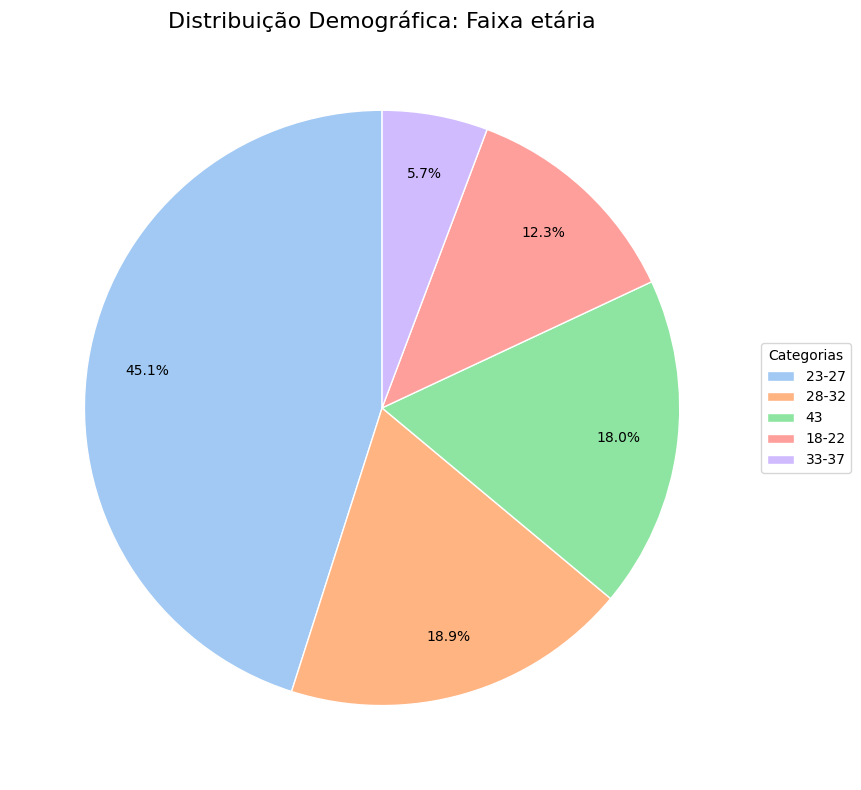

In [11]:
gera_pizza(dados_limpos, 'Q1', 'Faixa etária')

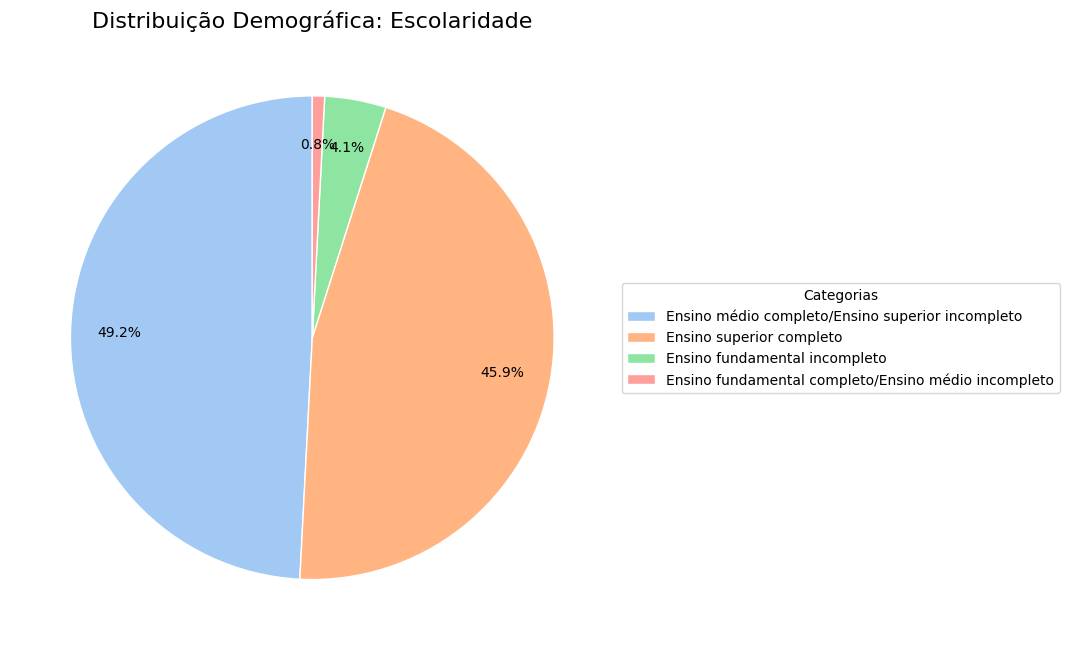

In [12]:
gera_pizza(dados_limpos, 'Q2', 'Escolaridade')

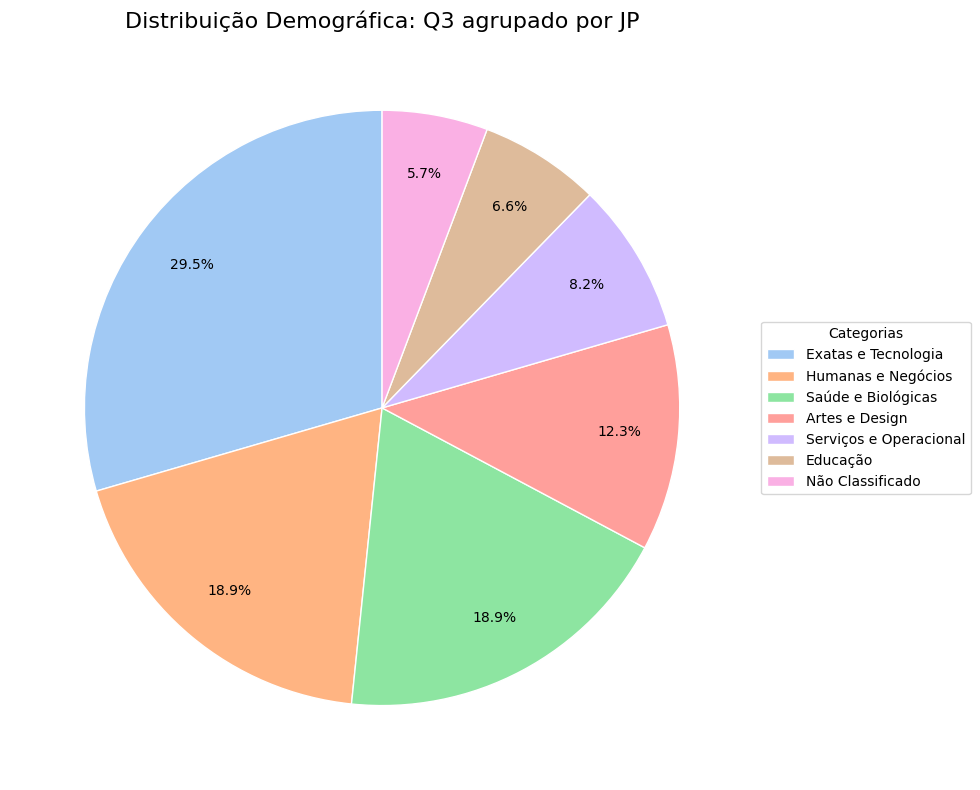

In [13]:
gera_pizza(dados_limpos, 'Q3_Agrupada', 'Q3 agrupado por JP')

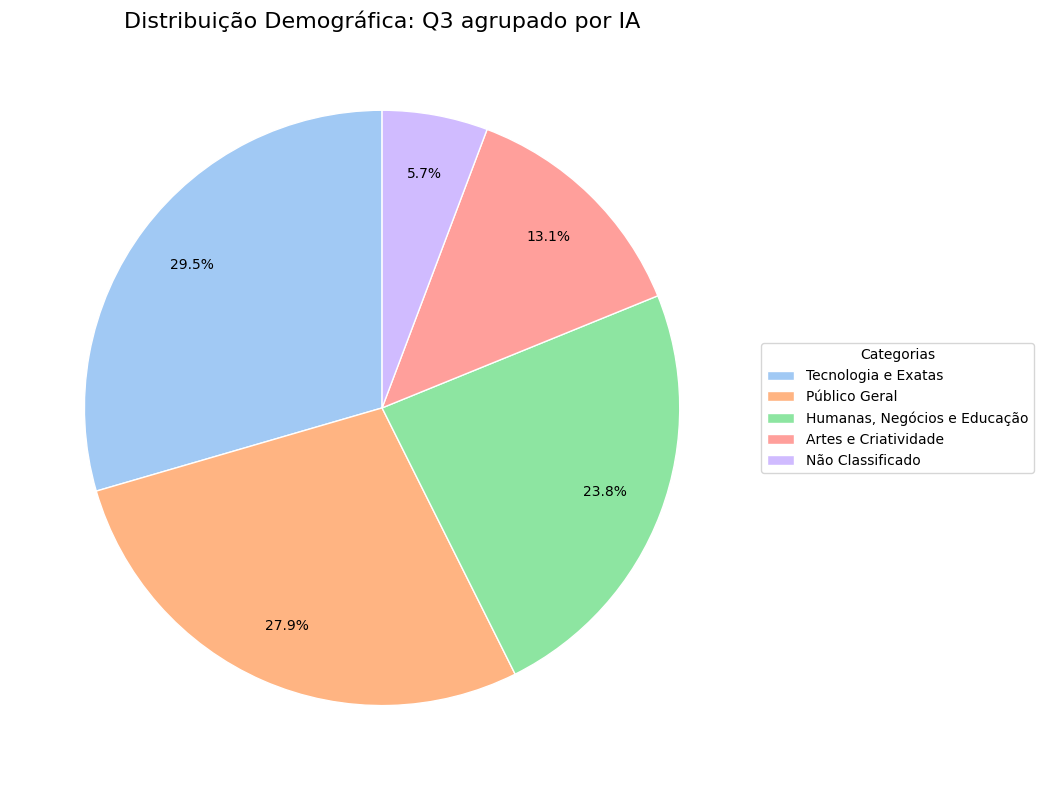

In [14]:
gera_pizza(dados_limpos, 'Perfil_Impacto_IA', 'Q3 agrupado por IA')

<Axes: ylabel='Q1'>

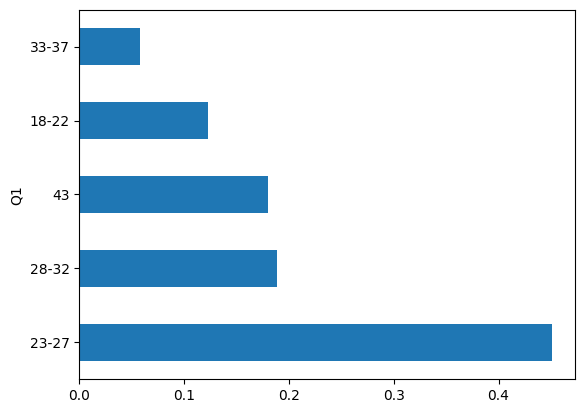

In [16]:
porcetagem_idade = dados_limpos['Q1'].value_counts(normalize=True)
porcetagem_idade.plot(kind='barh', stacked=True)

In [17]:
def gera_graficos_boxplot(dado, pergunta, nome_do_perfil="Perfil"):
    respostas = ['Q4','Q5','Q6','Q7','Q8','Q9','Q10','Q11','Q12','Q13','Q14', 'Q16', 'Q18']


    dado_temp = dado.copy()


    dado_temp[pergunta] = dado_temp[pergunta].apply(
        lambda x: textwrap.fill(str(x), width=20) if pd.notna(x) else x
    )


    grupos_quebrados = sorted(dado_temp[pergunta].dropna().unique())

    sns.set_theme(style='whitegrid')

    for resposta in respostas:
        plt.figure(figsize=(10, 6))

        sns.boxplot(
            x=pergunta,
            y=resposta,
            data=dado_temp,
            order=grupos_quebrados,
            palette='Blues'
        )


        plt.xticks(rotation=45, ha='center', fontsize=10)

        plt.title(f'Distribuição de Respostas: {resposta} por {nome_do_perfil}', fontsize=14)
        plt.xlabel(nome_do_perfil, fontsize=12)
        plt.ylabel(f'Nota ({resposta})', fontsize=12)

        plt.tight_layout()
        plt.show()

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


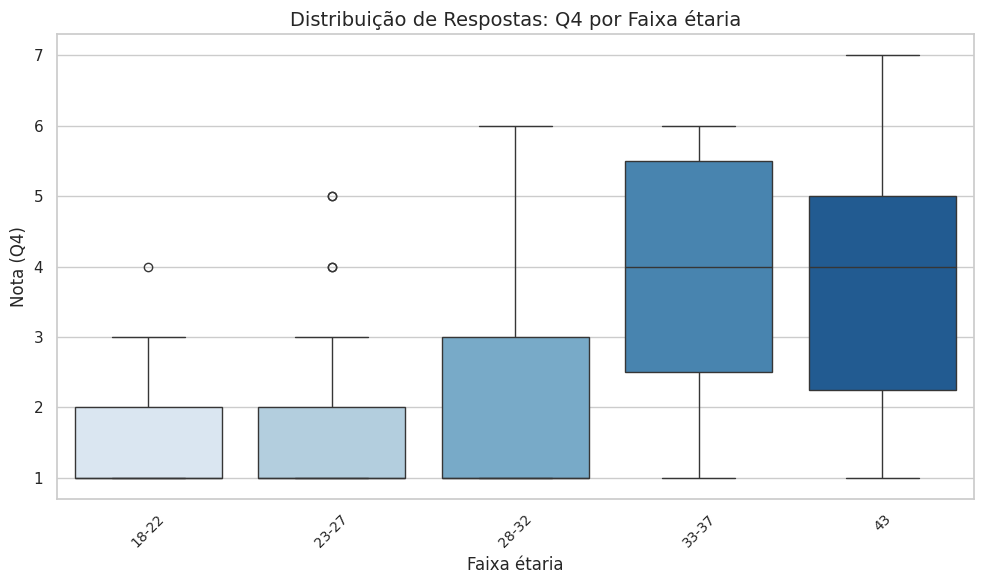

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


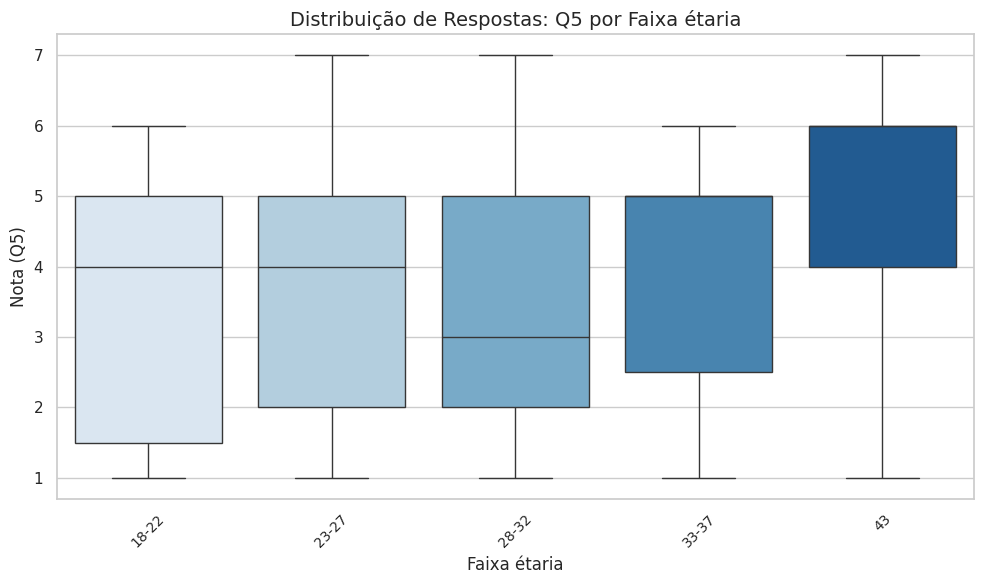

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


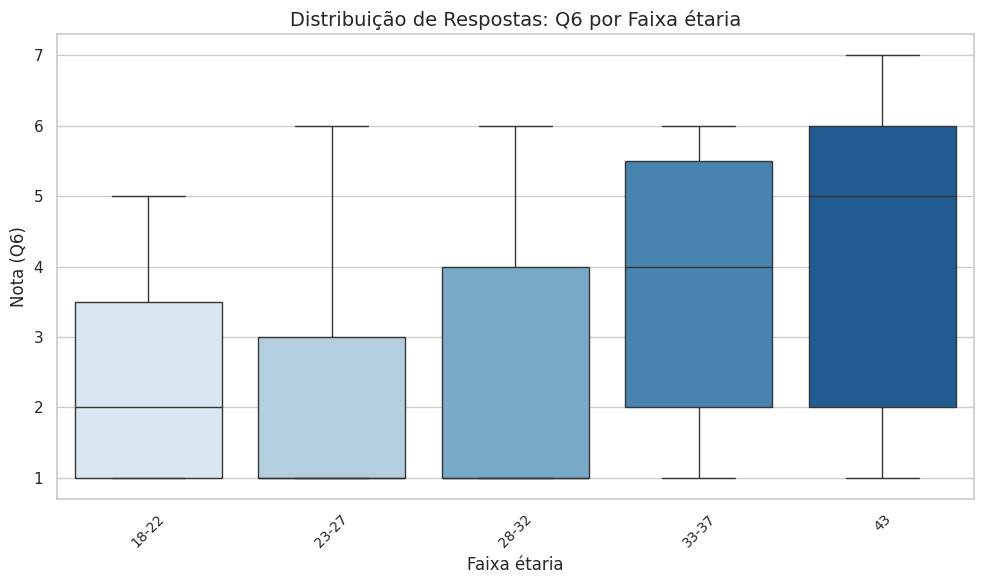

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


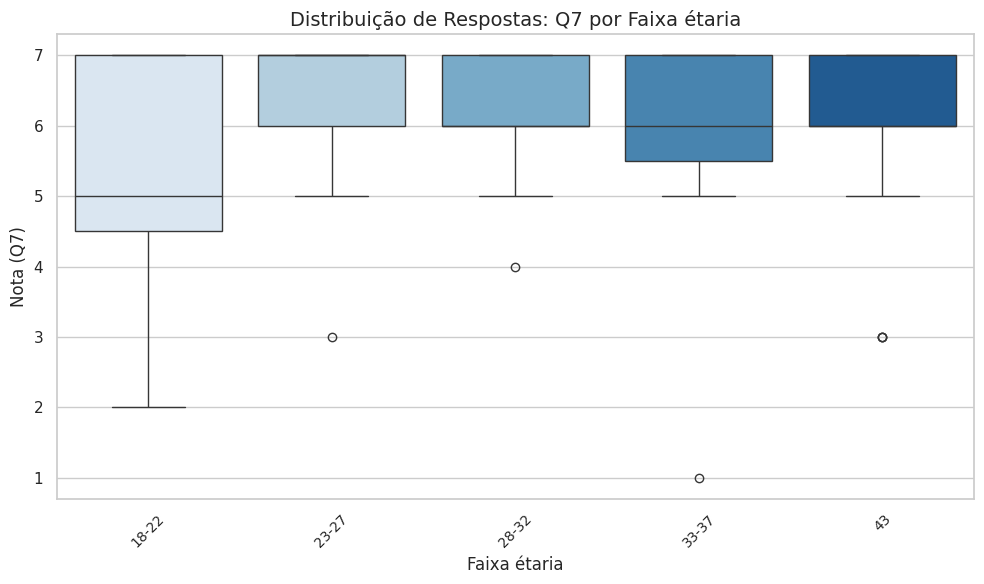

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


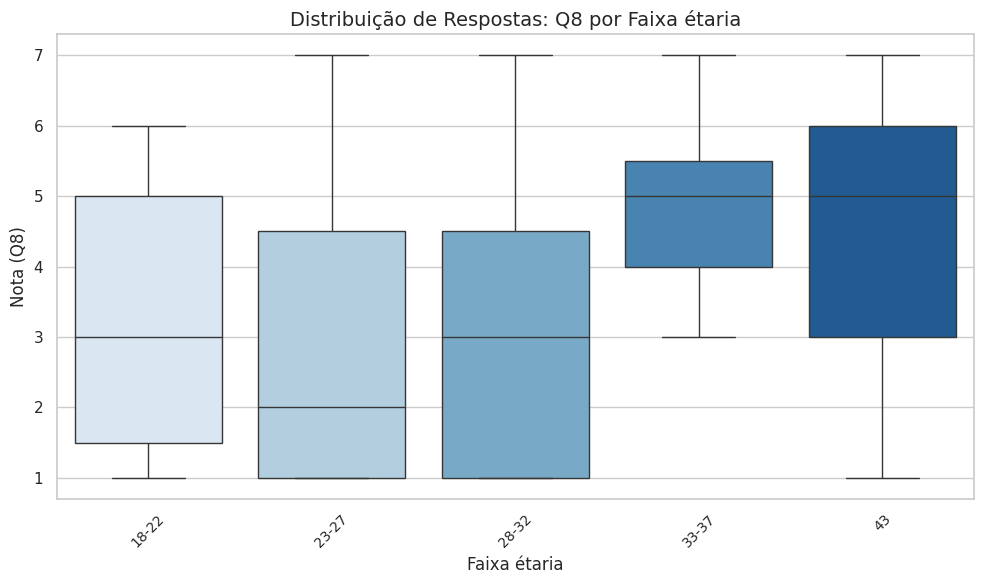

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


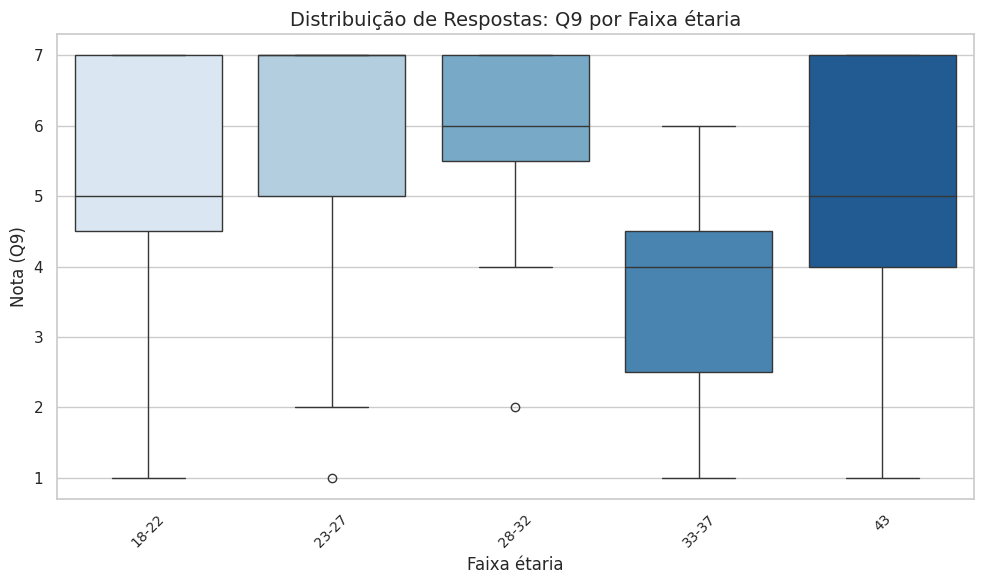

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


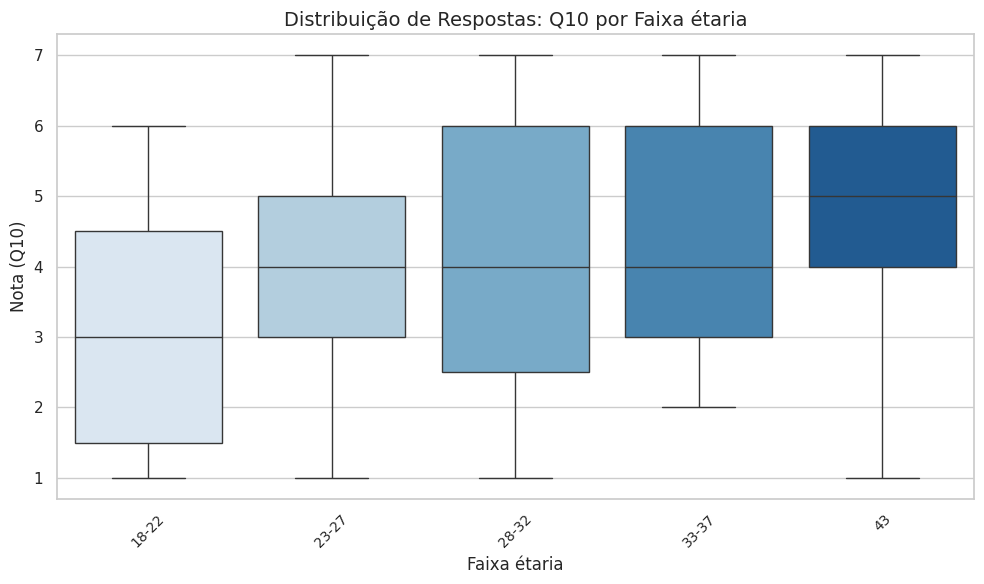

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


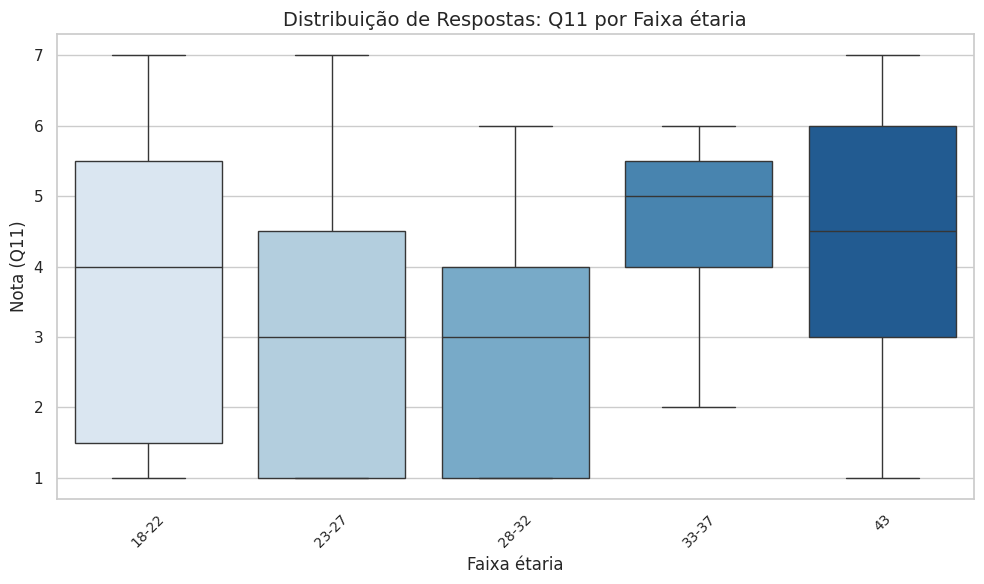

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


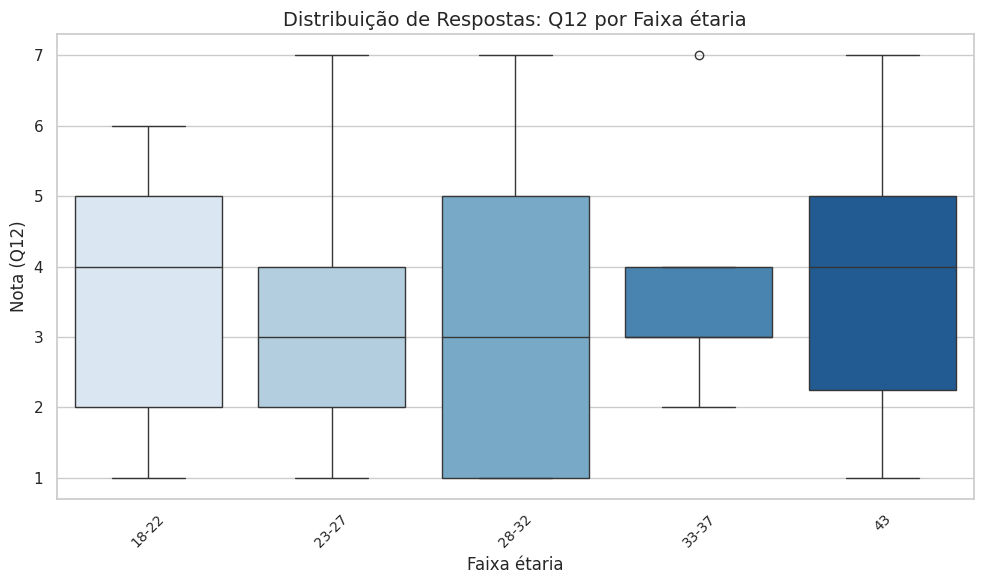

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


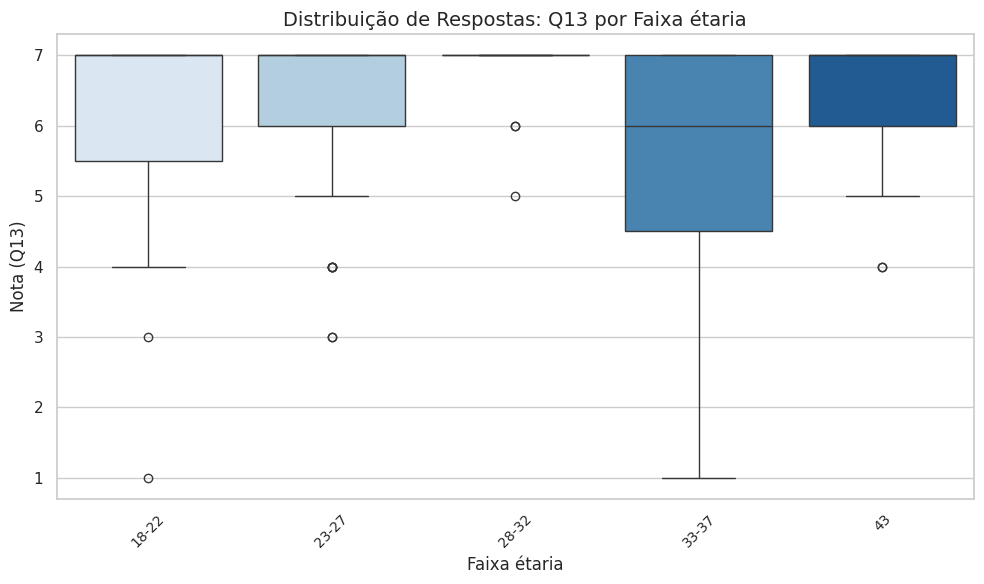

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


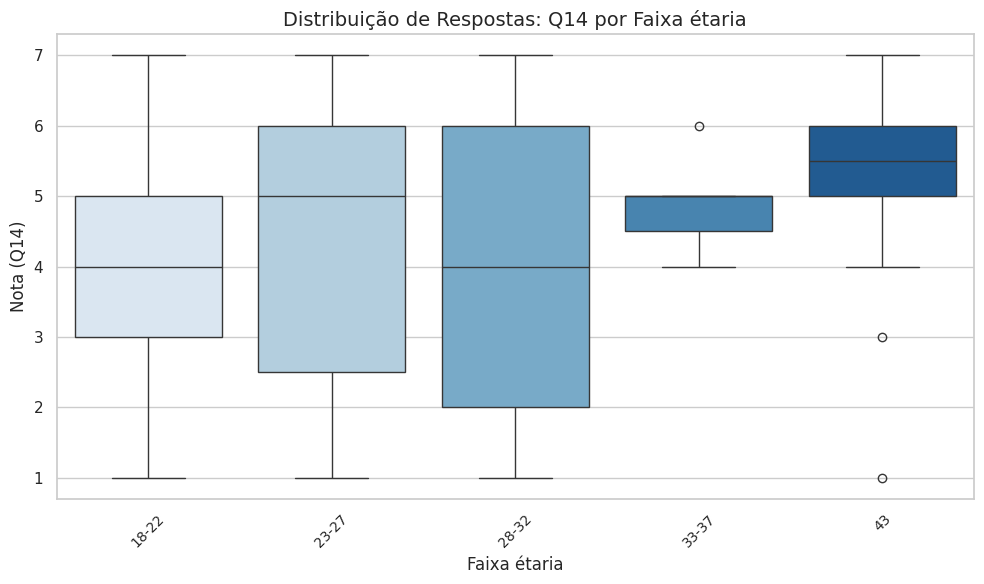

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


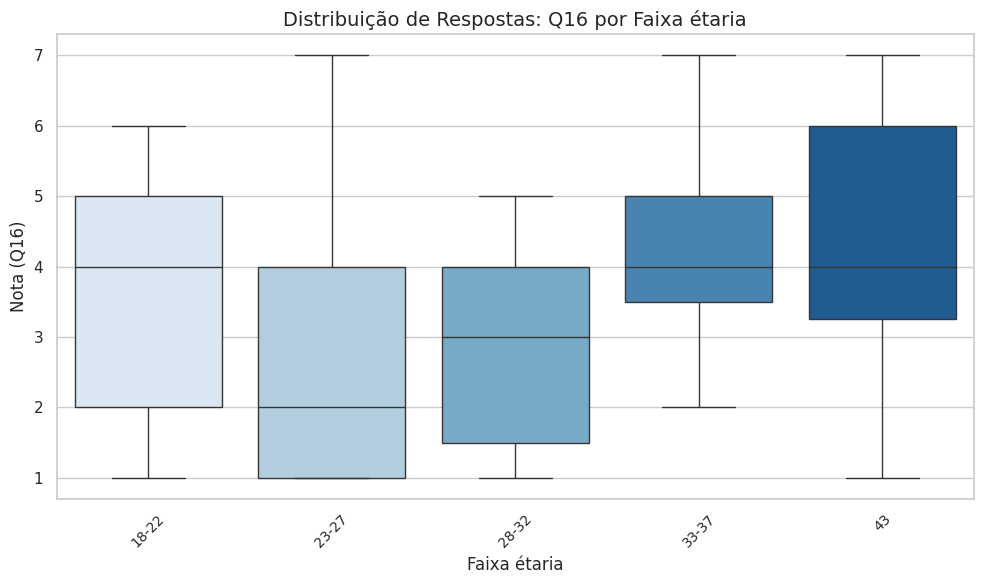

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


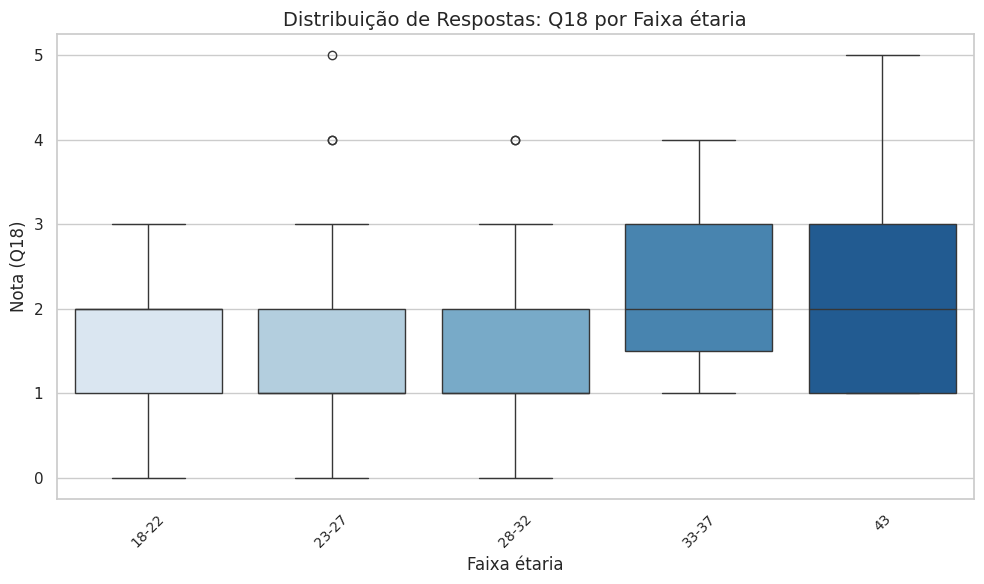

In [18]:
gera_graficos_boxplot(dados_limpos,'Q1','Faixa étaria')

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


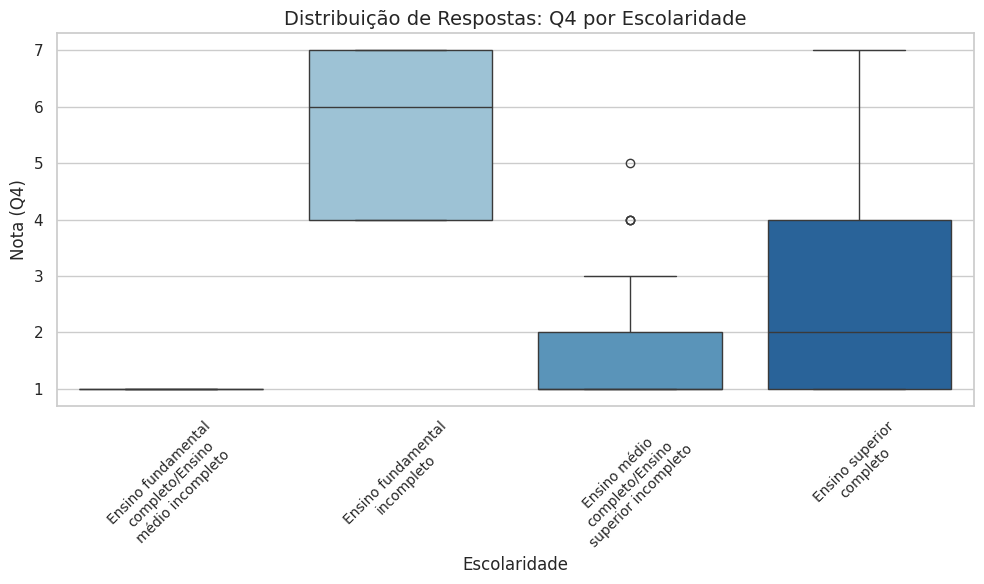

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


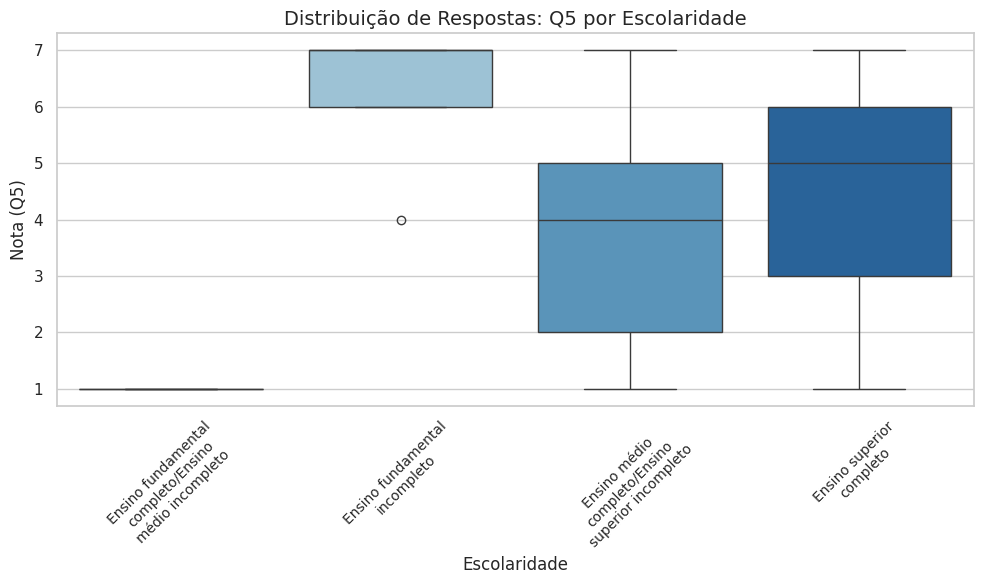

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


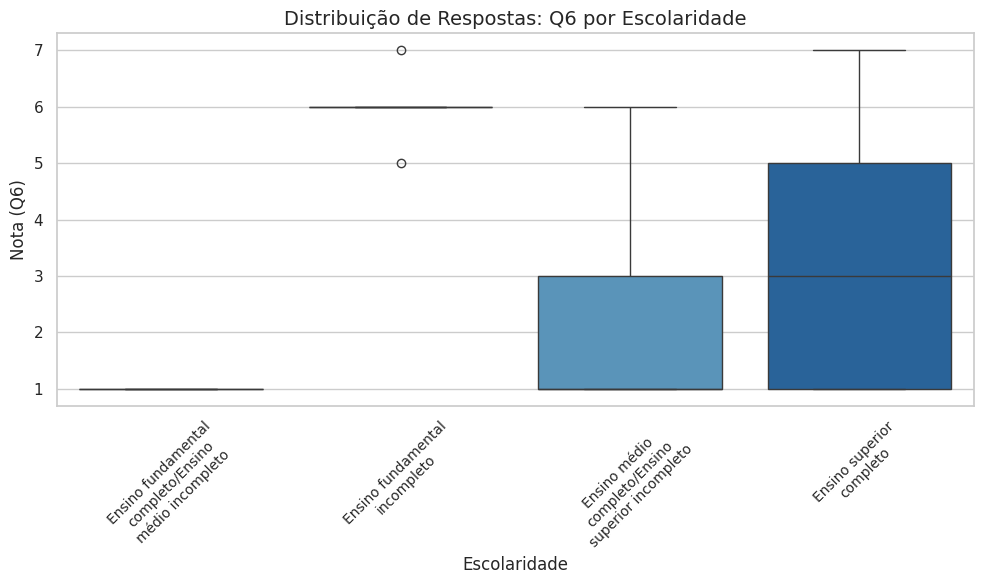

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


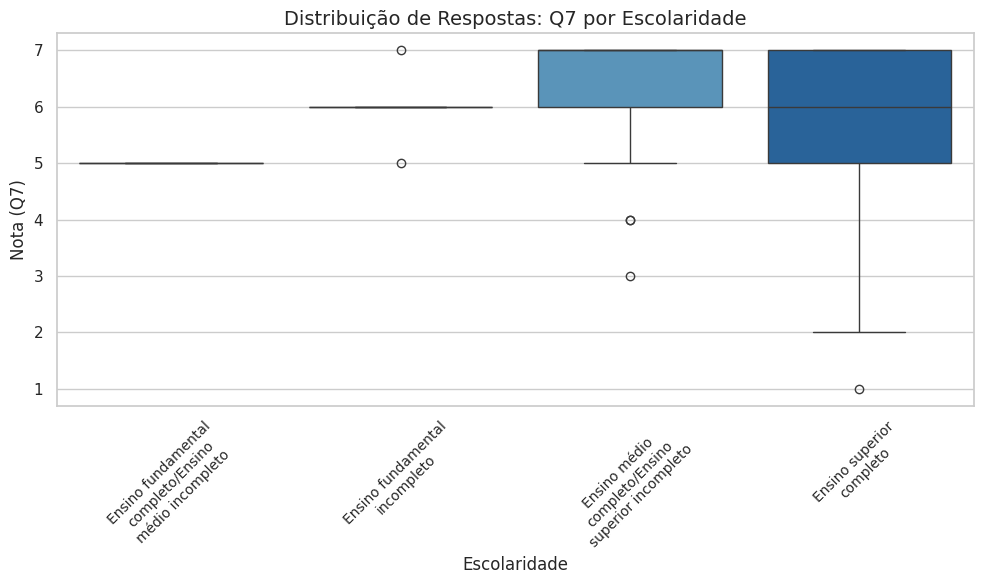

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


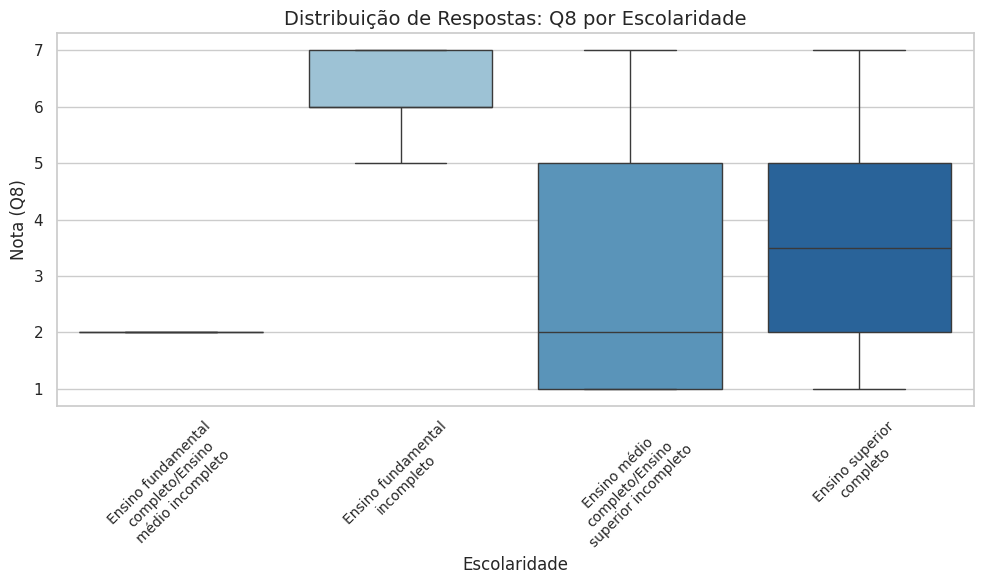

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


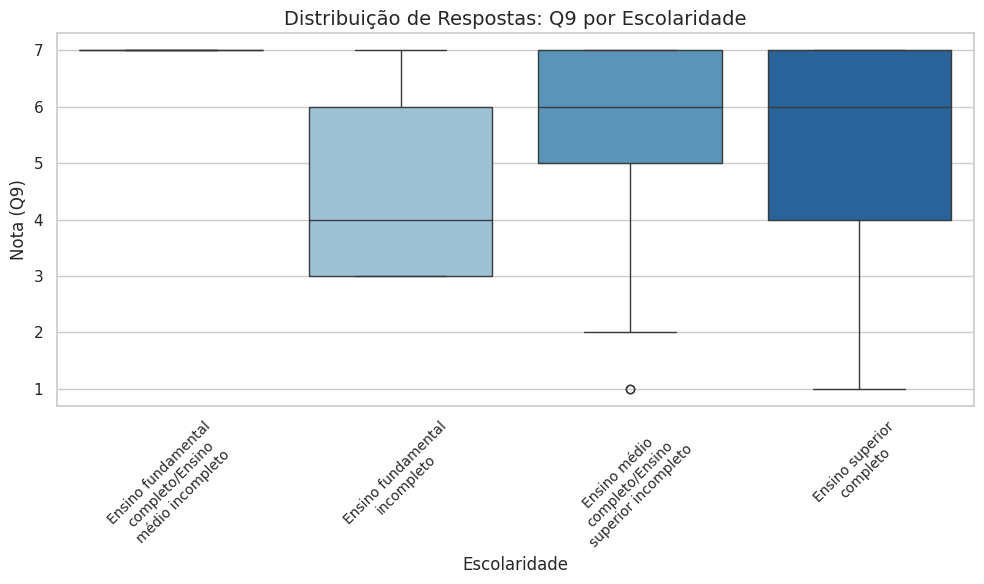

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


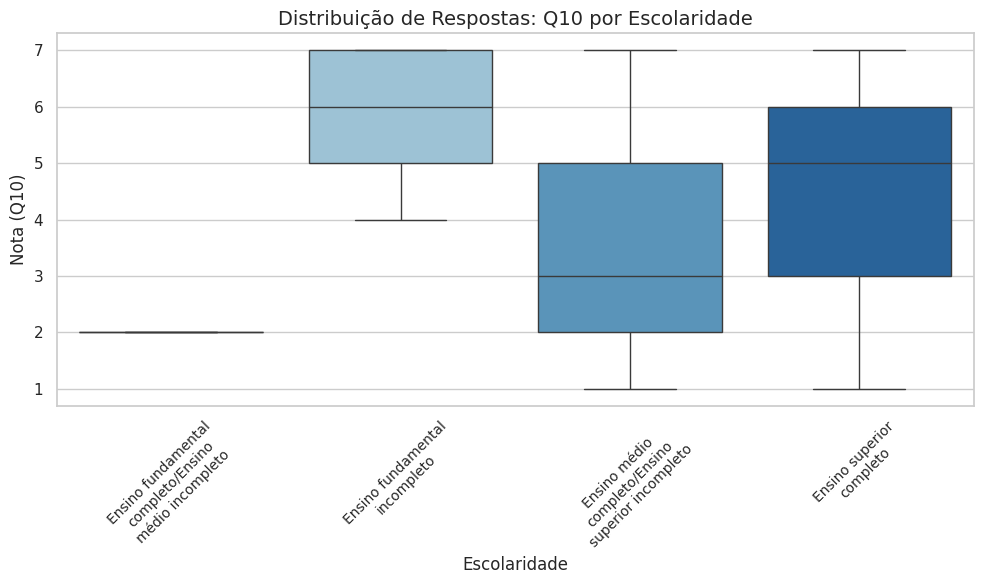

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


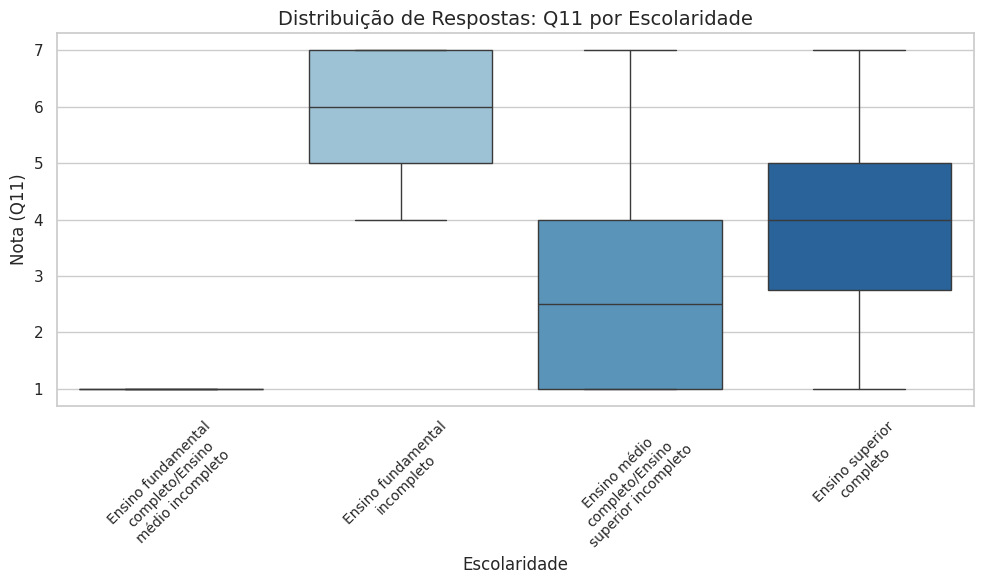

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


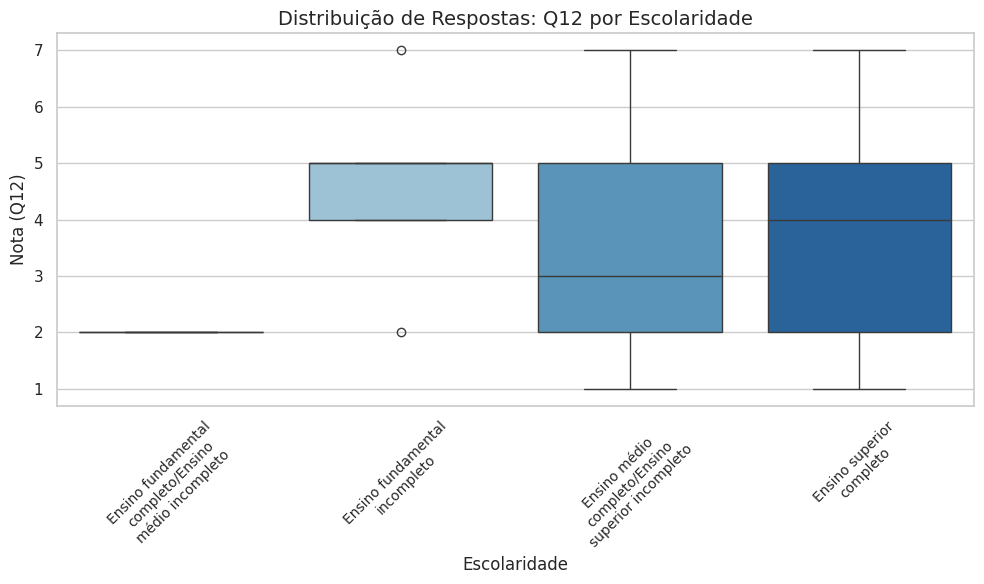

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


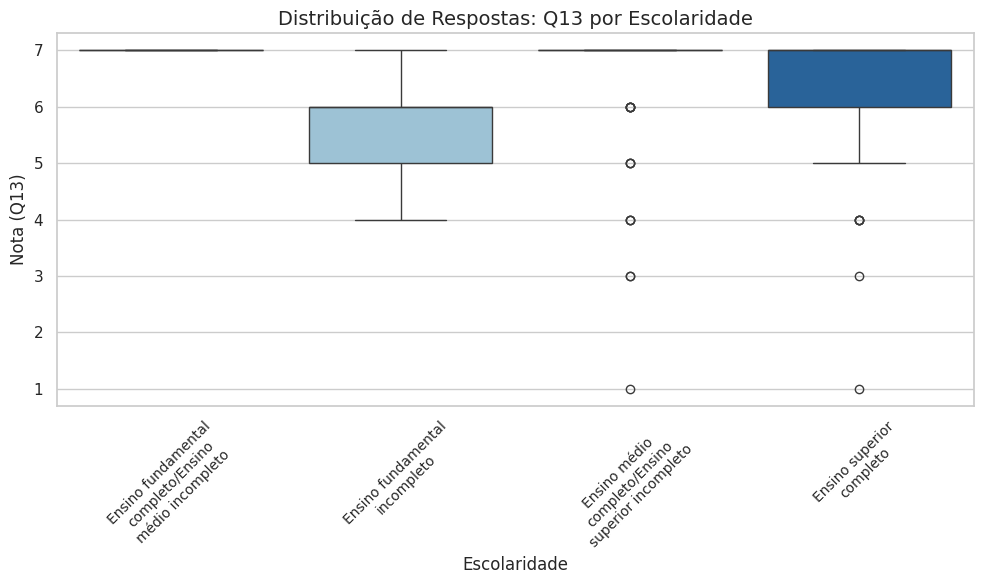

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


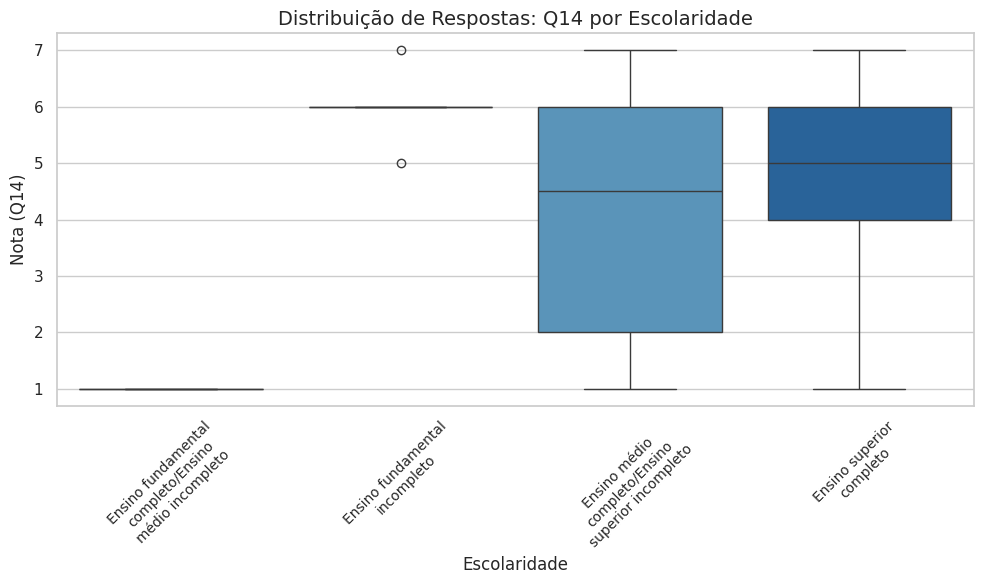

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


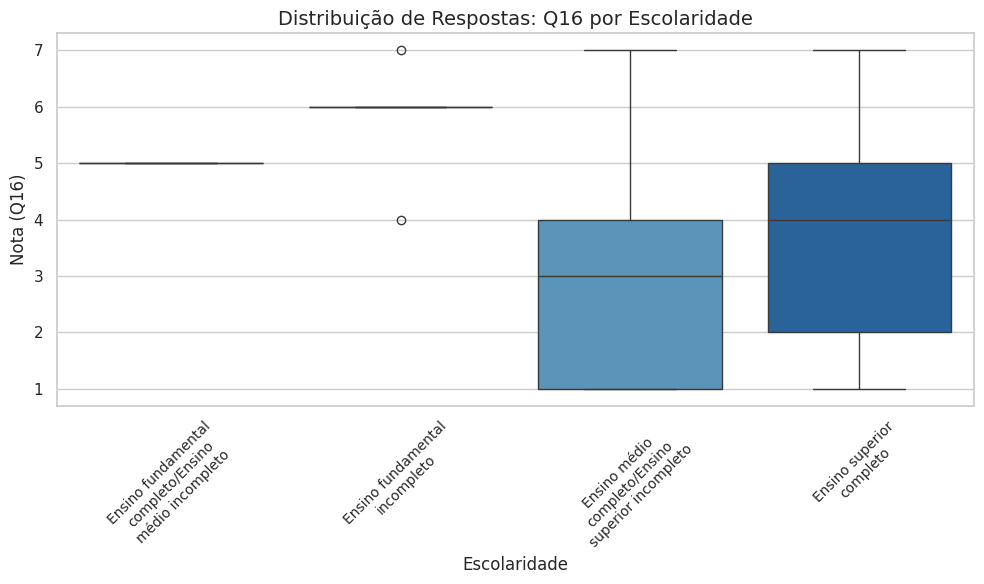

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


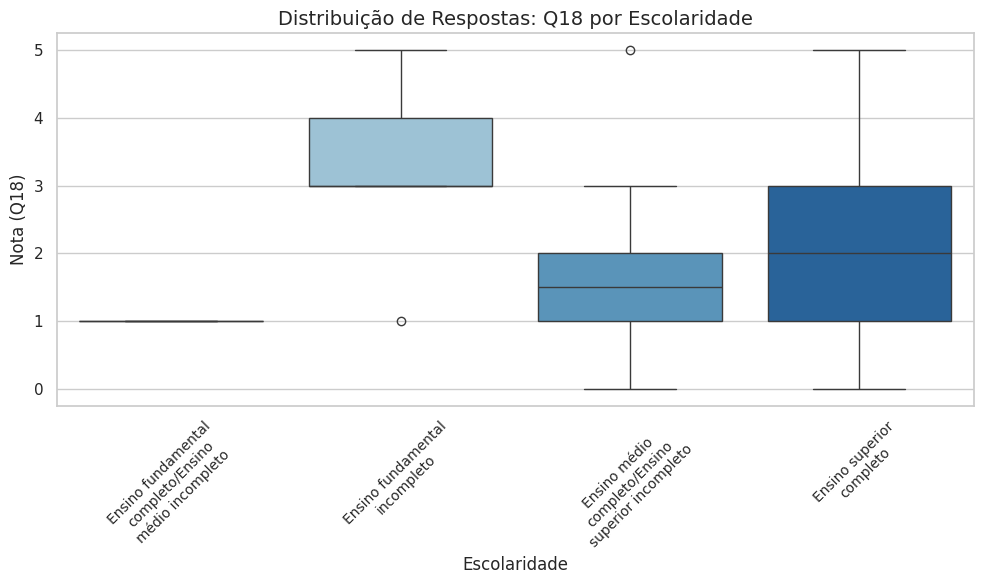

In [19]:
gera_graficos_boxplot(dados_limpos,'Q2','Escolaridade')

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


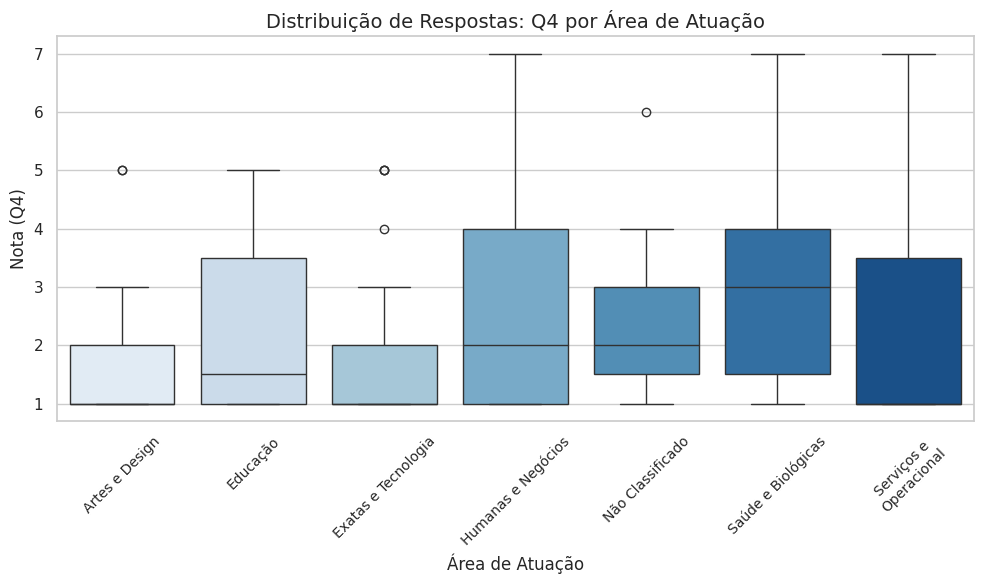

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


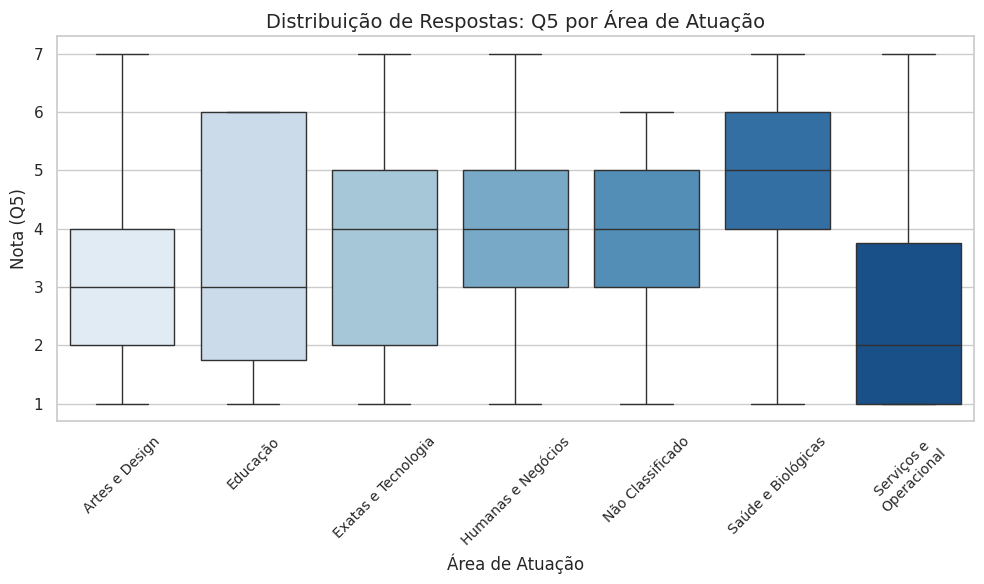

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


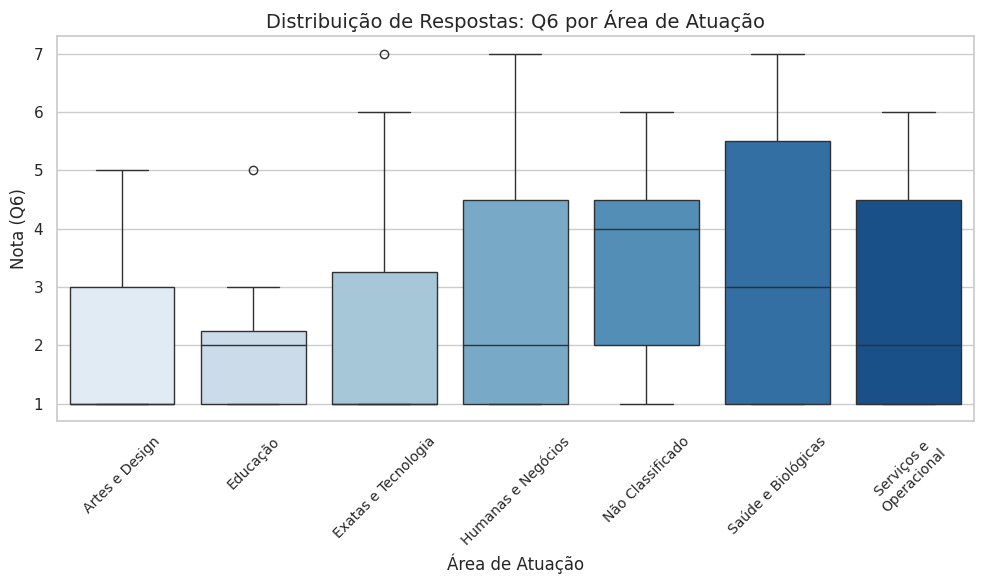

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


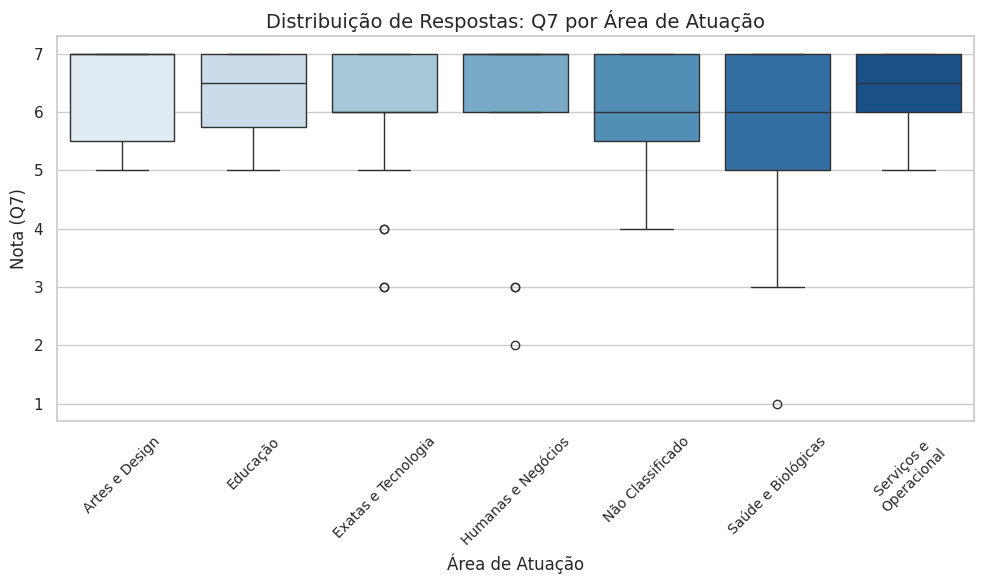

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


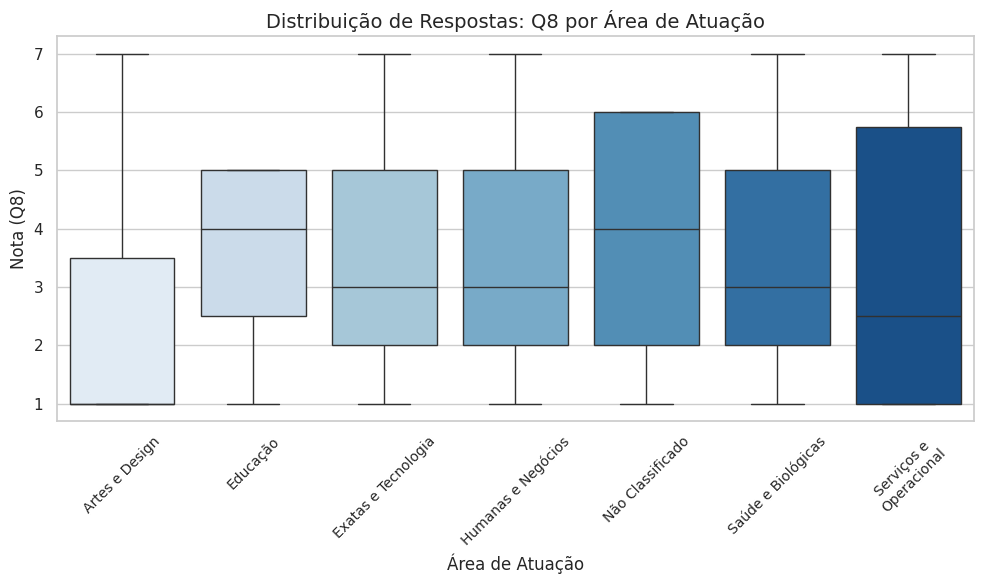

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


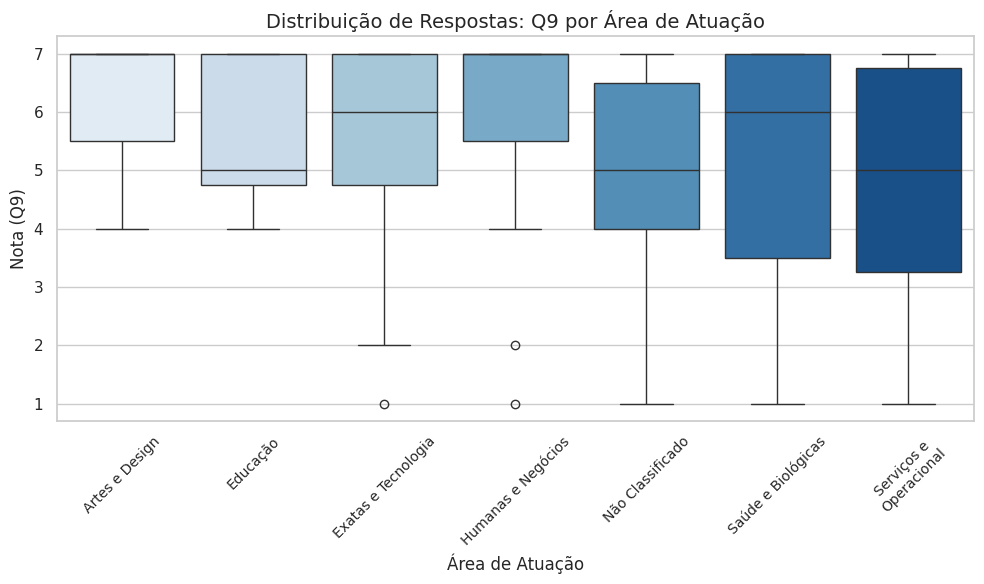

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


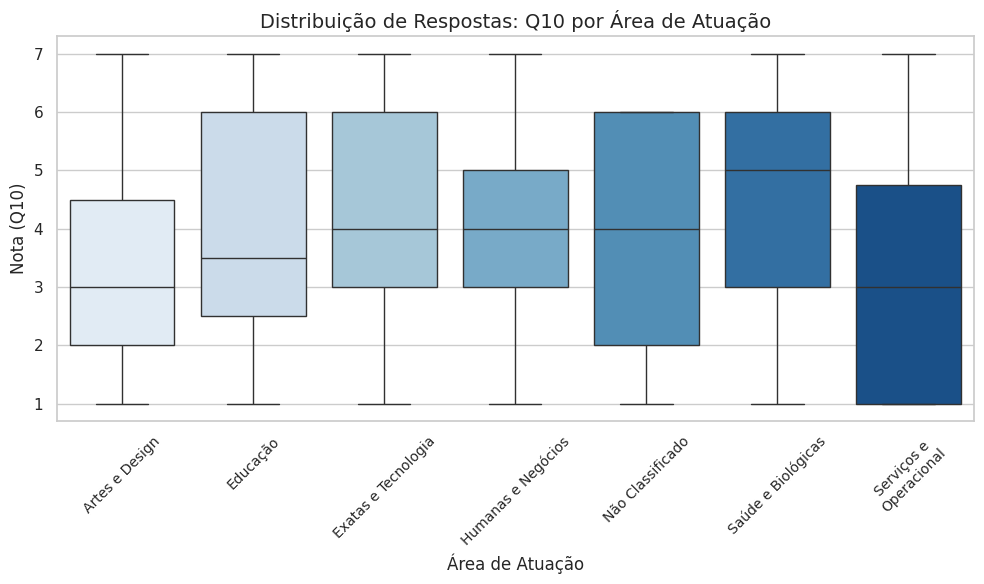

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


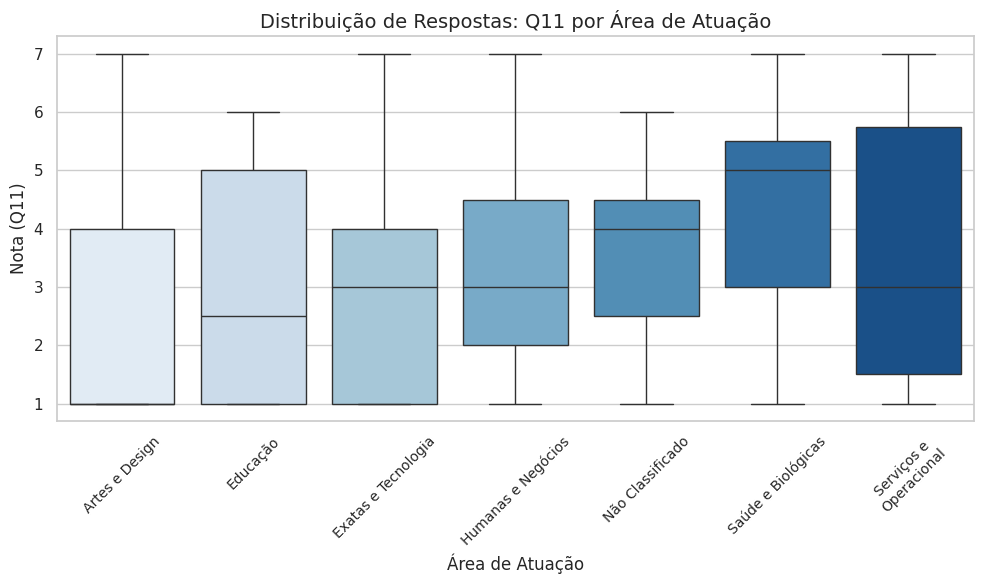

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


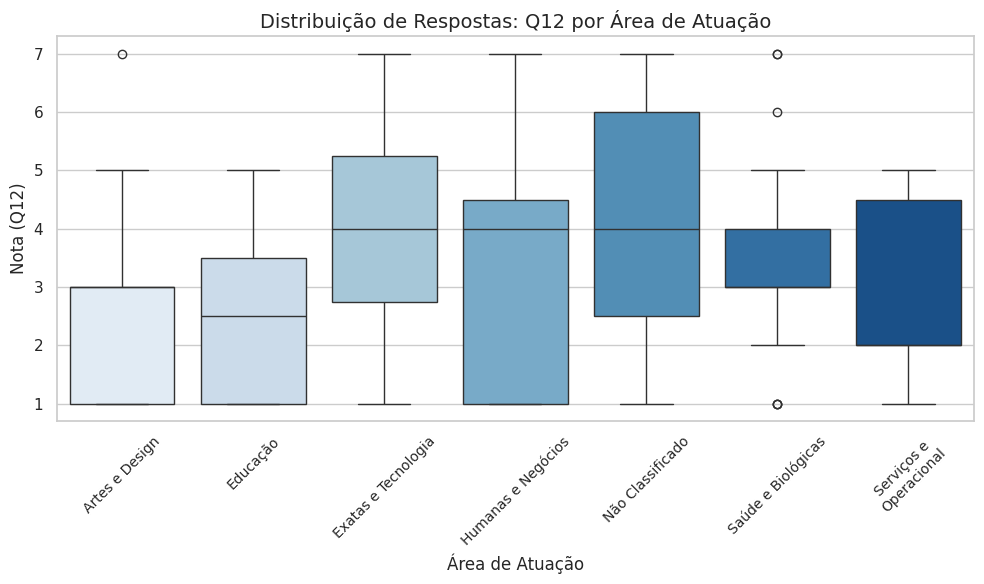

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


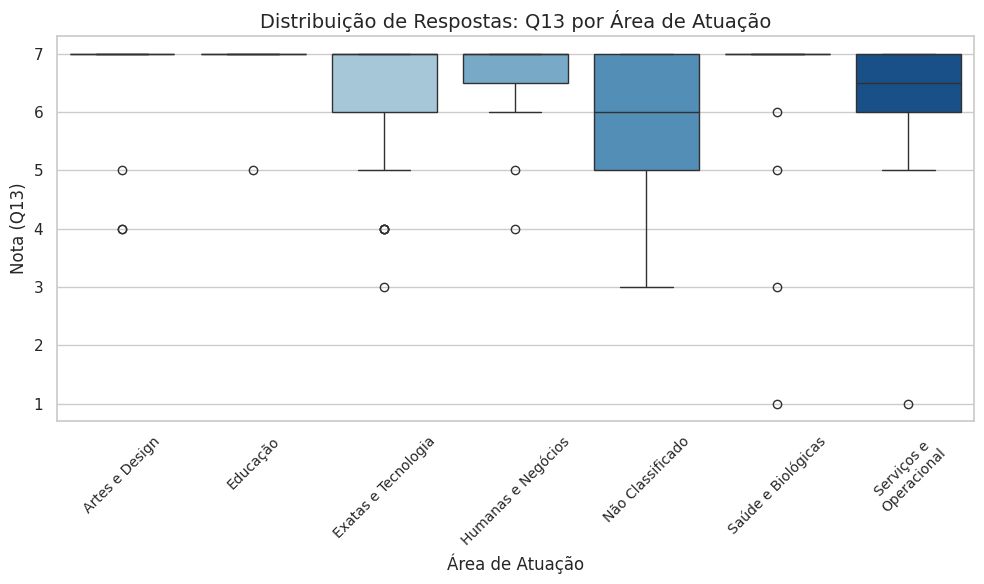

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


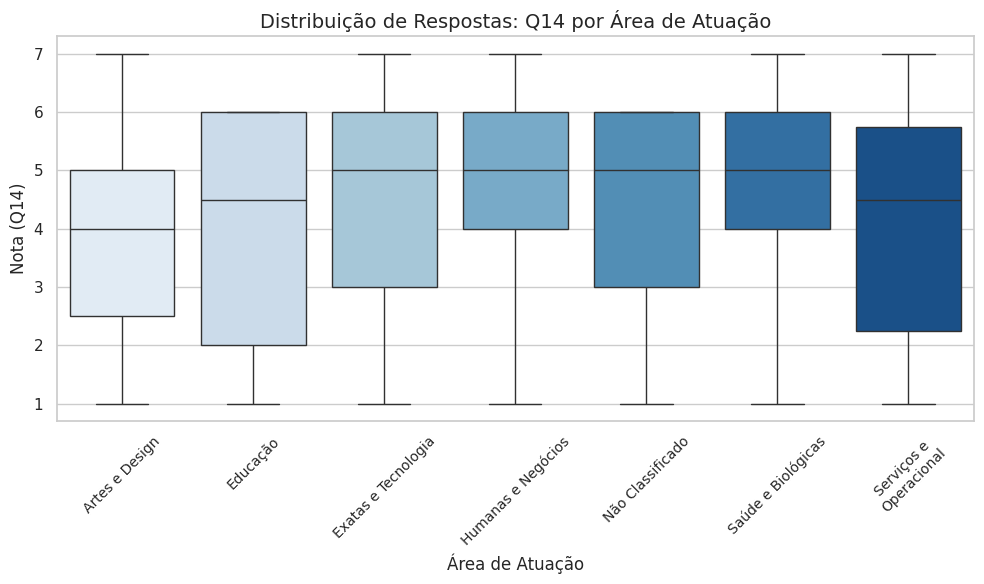

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


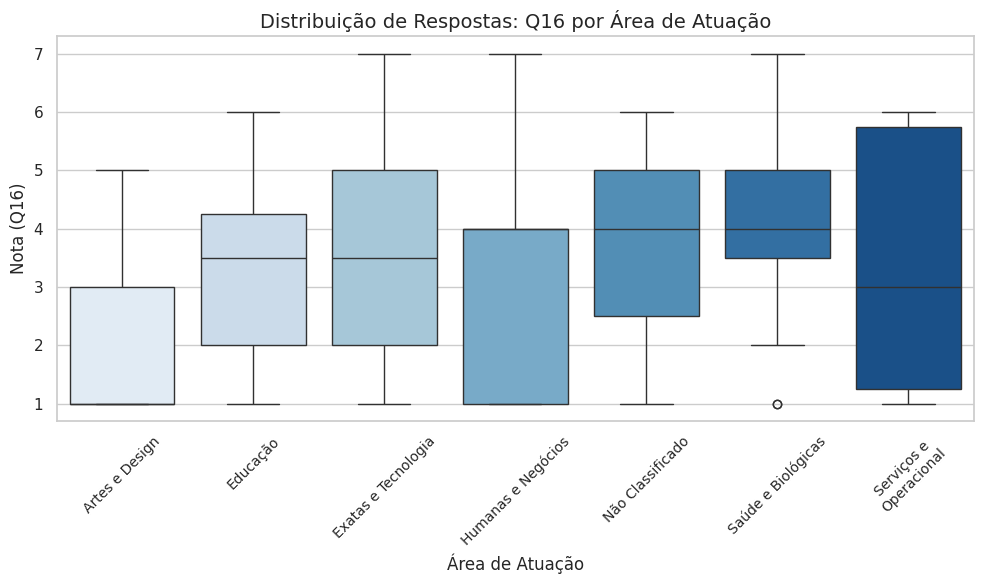

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


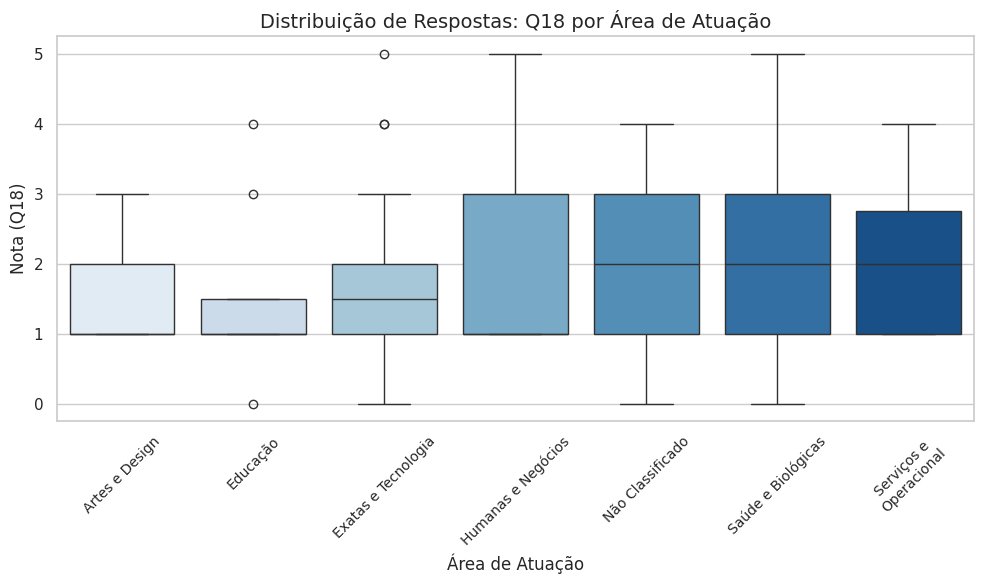

In [20]:
gera_graficos_boxplot(dados_limpos,'Q3_Agrupada', 'Área de Atuação')

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


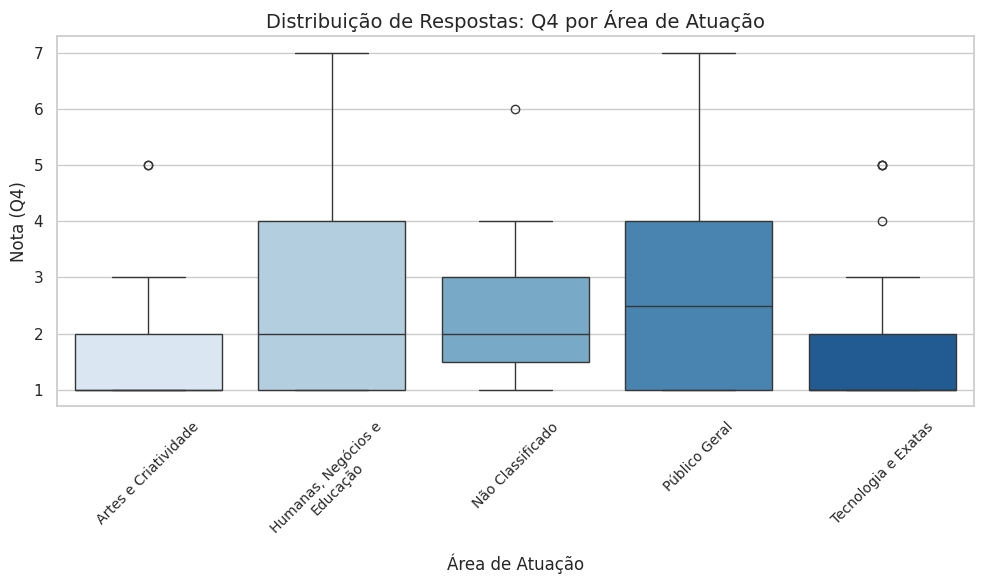

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


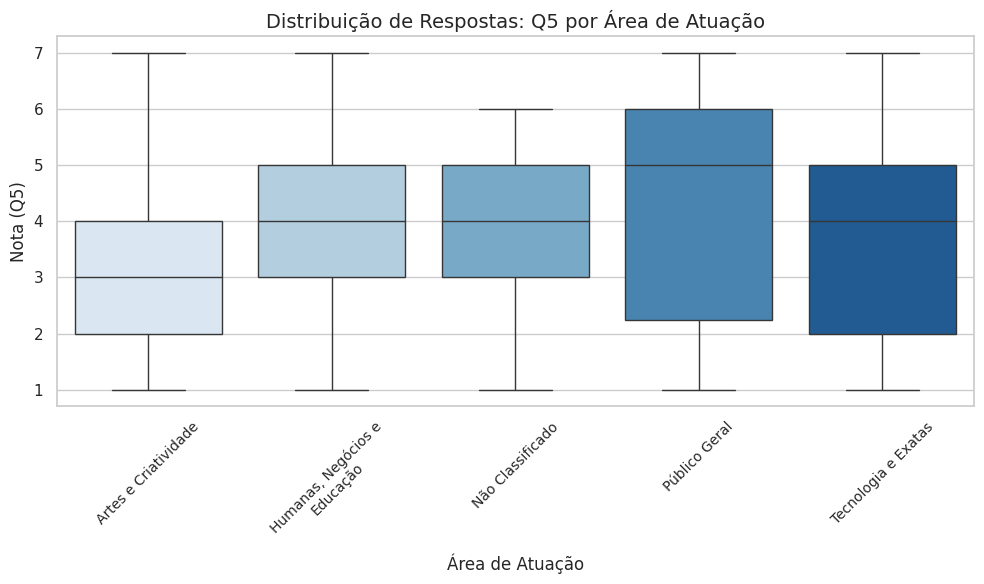

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


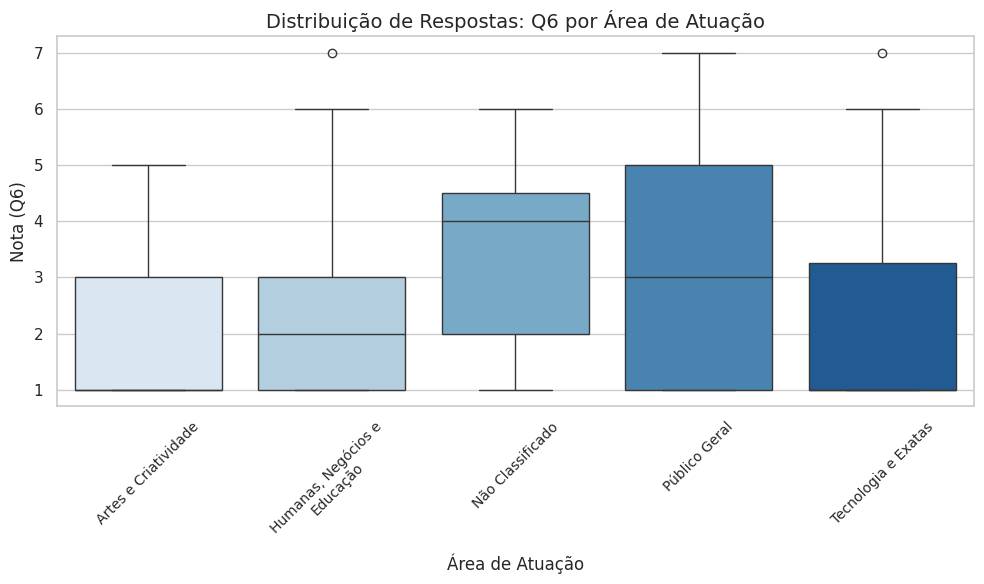

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


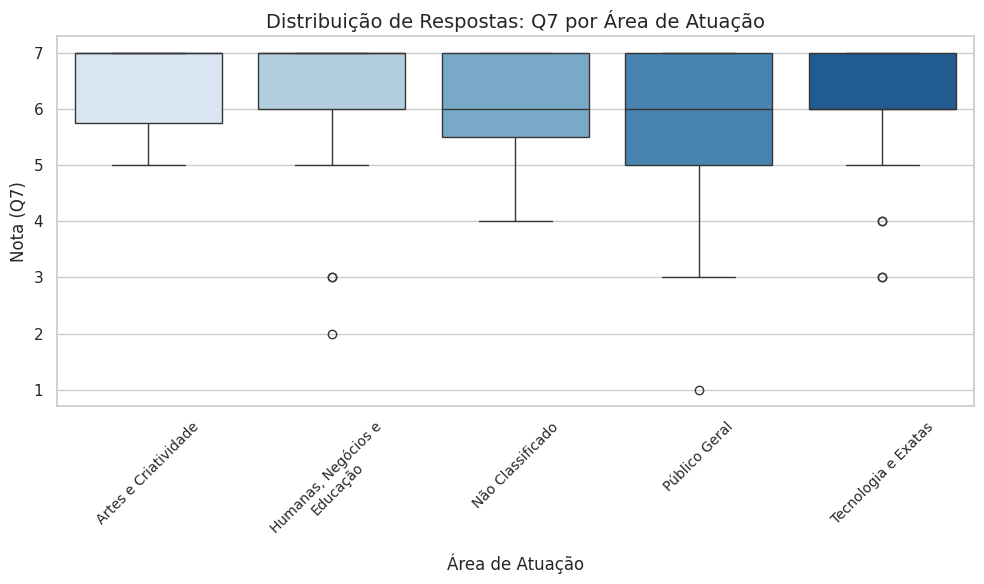

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


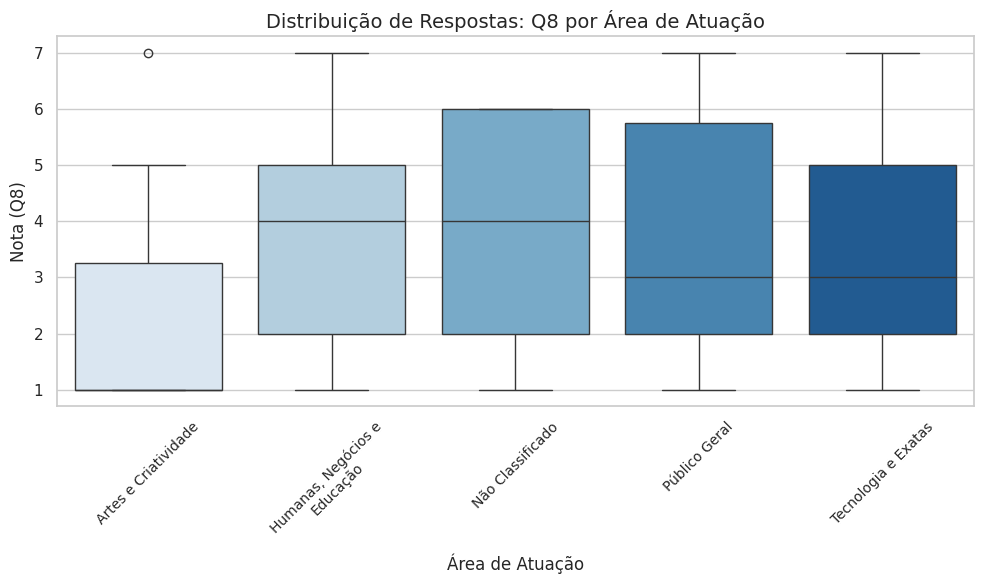

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


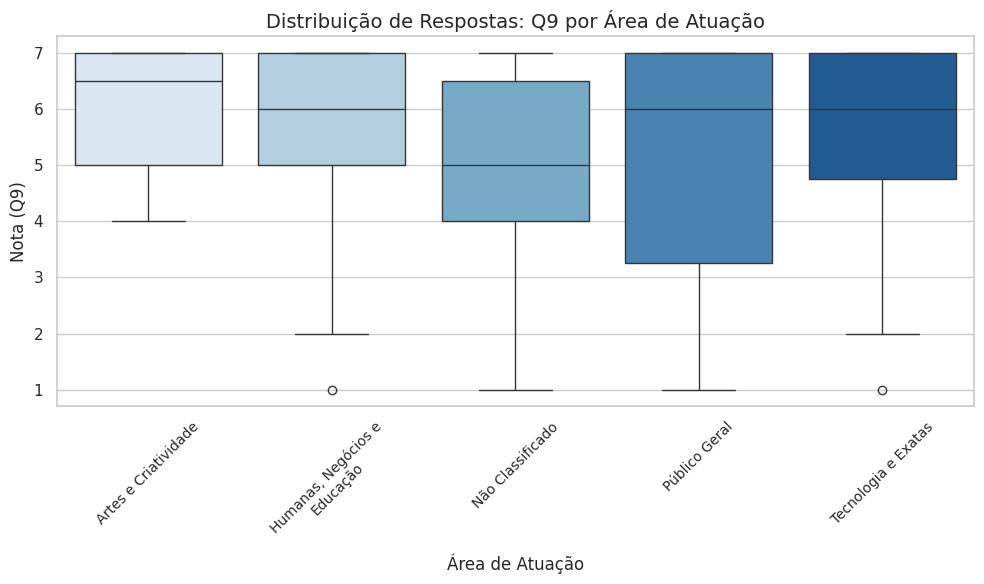

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


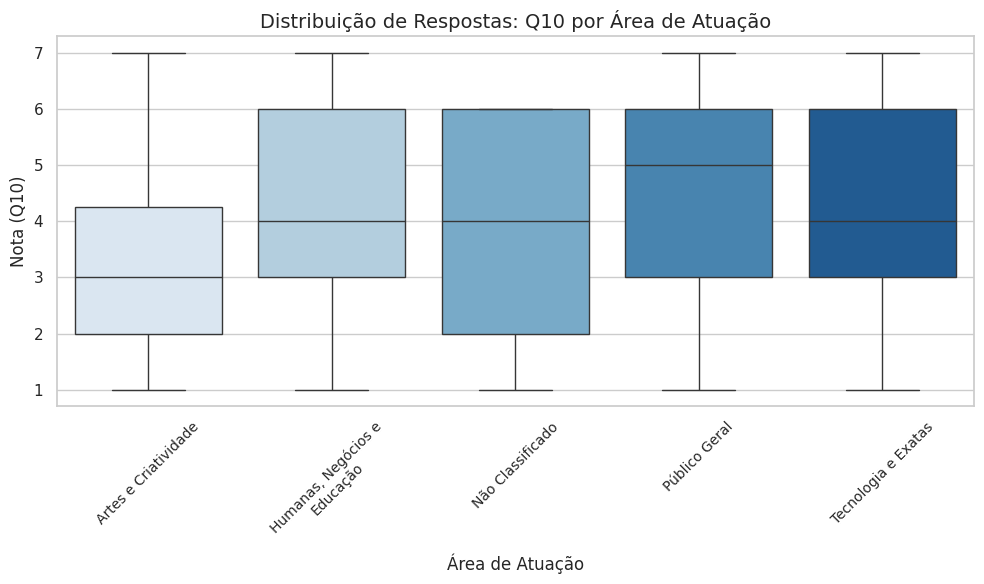

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


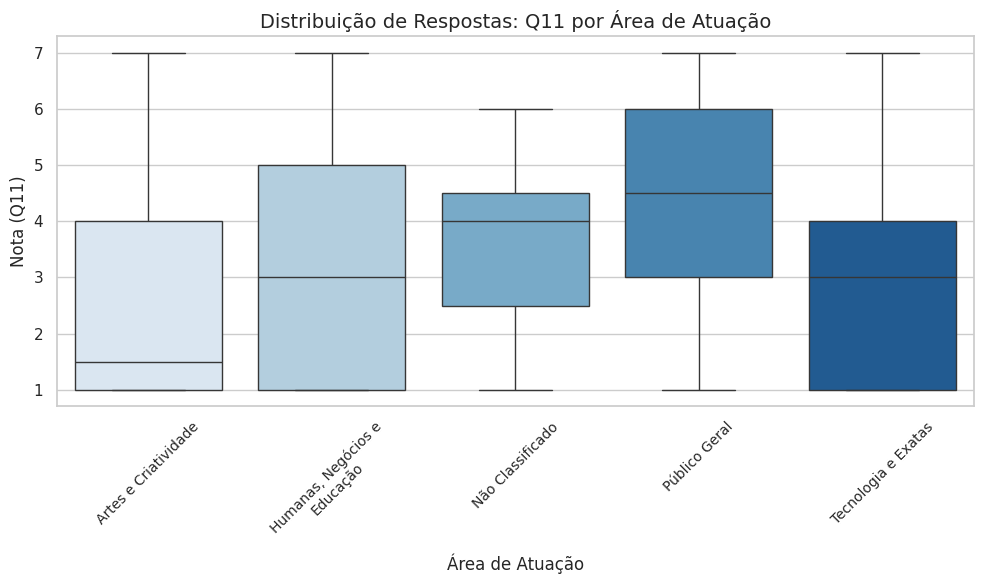

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


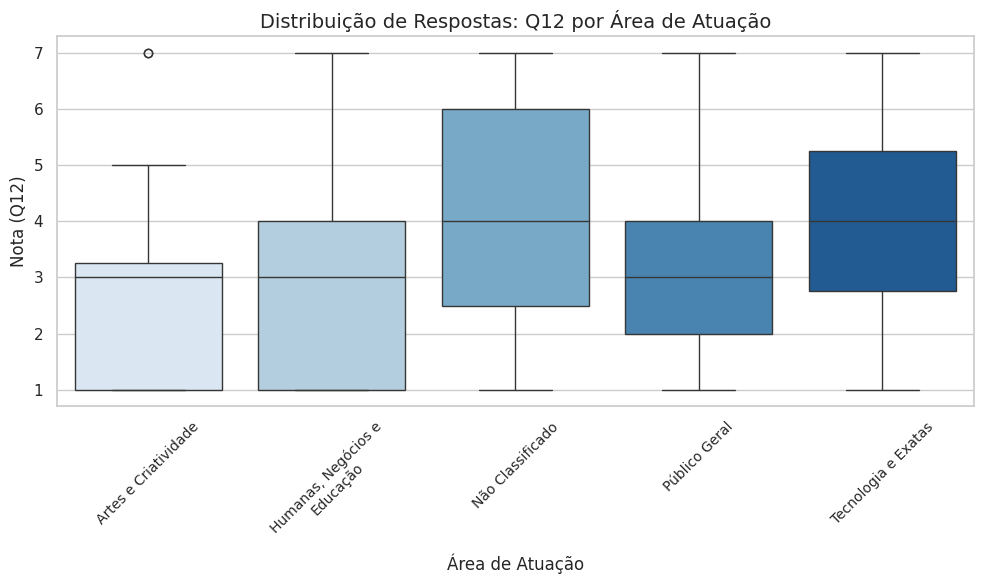

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


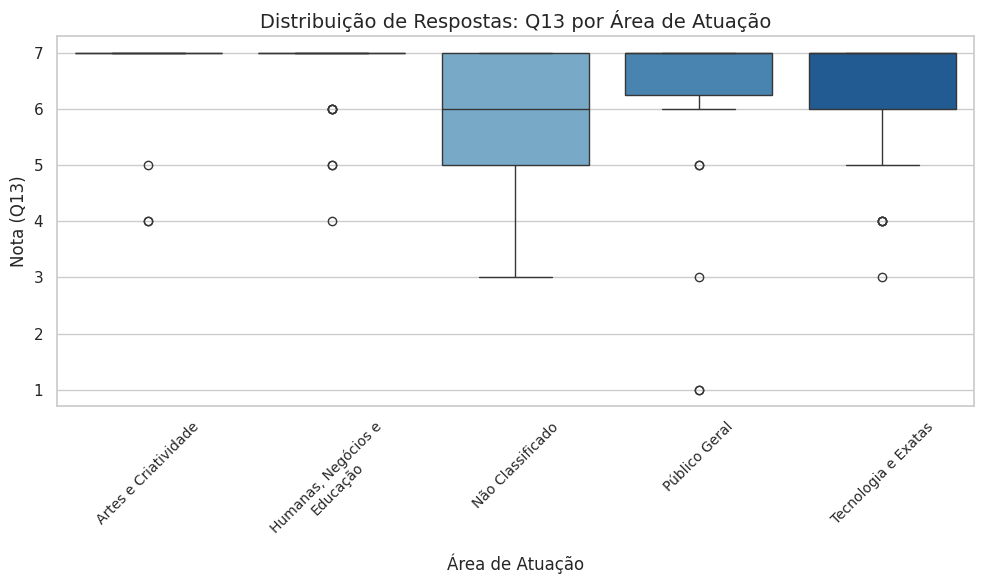

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


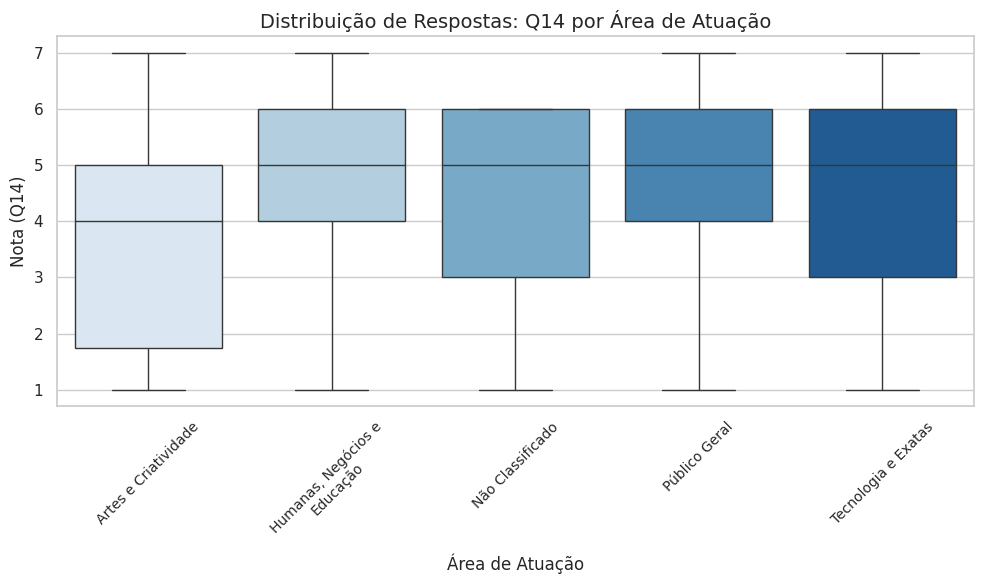

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


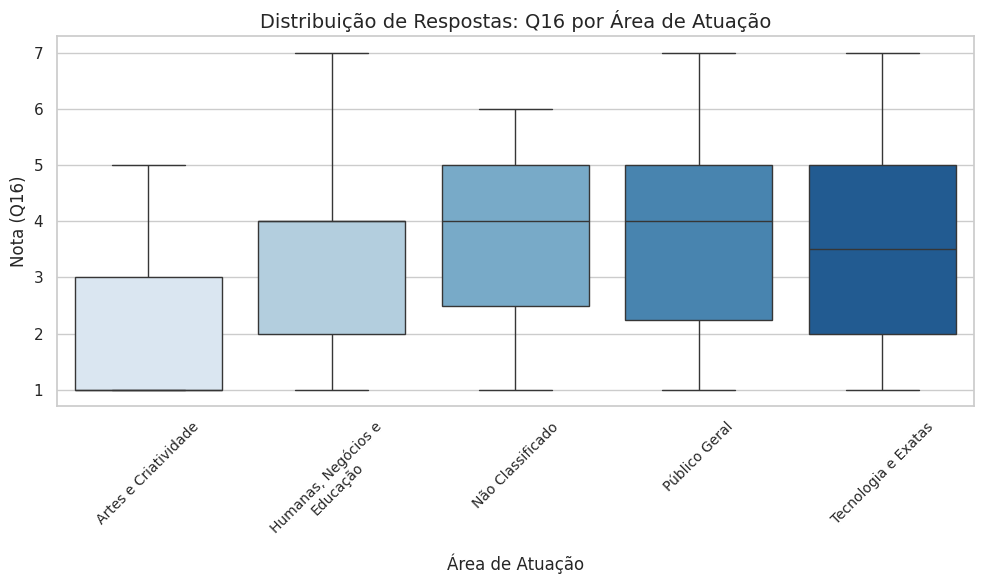

/tmp/ipykernel_16241/2633066897.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


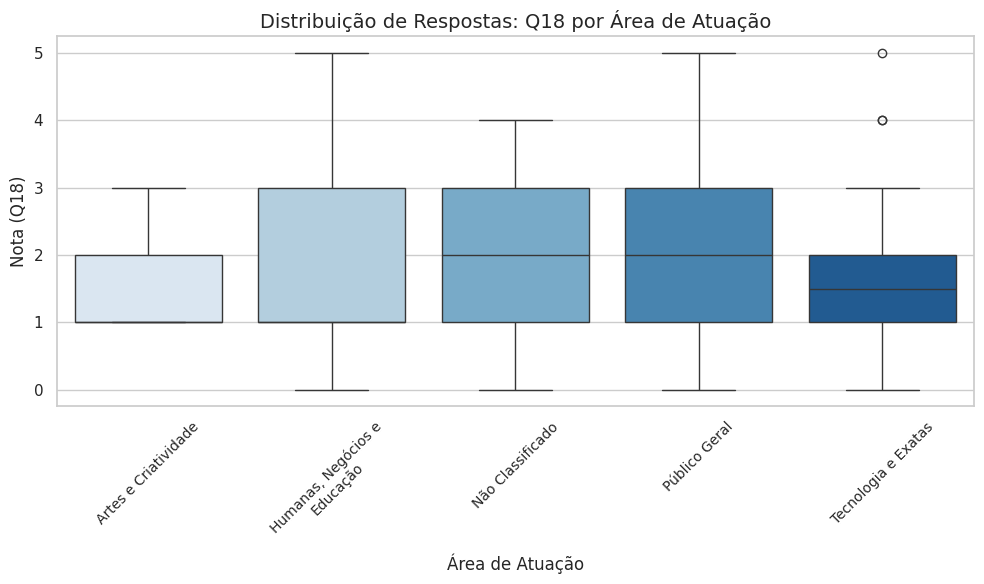

In [21]:
gera_graficos_boxplot(dados_limpos,'Perfil_Impacto_IA', 'Área de Atuação')

In [22]:
def calcular_medias_todos_grupos(data, qs, perfil):
    print(f'Calculando médias para todas as categorias de: {perfil}...\n')


    df_medias = data.groupby(perfil)[qs].mean().round(2)


    df_medias_transposta = df_medias.T


    display(df_medias_transposta)

    return df_medias_transposta

In [23]:
Qs = ['Q4','Q5','Q6','Q7','Q8','Q9','Q10','Q11','Q12','Q13','Q14','Q16', 'Q18']
df_medias_idade = calcular_medias_todos_grupos(dados_limpos, Qs, 'Q1')
df_medias_escolaridade = calcular_medias_todos_grupos(dados_limpos, Qs, 'Q2')
df_medias_area_atuacao = calcular_medias_todos_grupos(dados_limpos, Qs, 'Q3_Agrupada')
df_medias_perfil_ia = calcular_medias_todos_grupos(dados_limpos, Qs, 'Perfil_Impacto_IA')

Calculando médias para todas as categorias de: Q1...



Q1,18-22,23-27,28-32,33-37,43
Q4,1.73,1.71,2.09,3.86,4.05
Q5,3.47,3.67,3.61,3.86,5.09
Q6,2.40,1.98,2.57,3.71,4.18
Q7,5.40,6.38,6.22,5.57,5.95
Q8,3.27,3.04,3.00,4.86,4.55
Q9,5.13,5.76,6.00,3.57,5.05
Q10,3.07,3.91,4.09,4.43,4.86
Q11,3.60,3.09,2.87,4.57,4.45
Q12,3.53,3.44,3.13,3.71,3.77
Q13,5.93,6.40,6.83,5.29,6.36


Calculando médias para todas as categorias de: Q2...



Q2,Ensino fundamental completo/Ensino médio incompleto,Ensino fundamental incompleto,Ensino médio completo/Ensino superior incompleto,Ensino superior completo
Q4,1.0,5.6,1.70,2.73
Q5,1.0,6.2,3.48,4.20
Q6,1.0,6.0,2.00,3.05
Q7,5.0,6.0,6.32,5.91
Q8,2.0,6.2,2.93,3.75
Q9,7.0,4.6,5.68,5.30
Q10,2.0,5.8,3.40,4.61
Q11,1.0,5.8,2.97,3.79
Q12,2.0,4.6,3.35,3.52
Q13,7.0,5.6,6.43,6.32


Calculando médias para todas as categorias de: Q3_Agrupada...



Q3_Agrupada,Artes e Design,Educação,Exatas e Tecnologia,Humanas e Negócios,Não Classificado,Saúde e Biológicas,Serviços e Operacional
Q4,1.80,2.38,1.83,2.74,2.57,2.96,2.3
Q5,3.13,3.50,3.94,4.22,3.86,4.61,2.9
Q6,2.07,2.12,2.22,2.78,3.43,3.39,2.8
Q7,6.27,6.25,6.11,6.26,6.00,5.74,6.3
Q8,2.40,3.50,3.56,3.65,3.86,3.57,3.4
Q9,6.13,5.50,5.42,5.87,4.86,5.26,4.7
Q10,3.27,3.88,4.14,4.17,3.86,4.74,3.2
Q11,2.60,3.00,3.17,3.57,3.57,4.30,3.7
Q12,2.60,2.62,4.03,3.39,4.14,3.61,2.8
Q13,6.47,6.75,6.25,6.61,5.71,6.43,5.9


Calculando médias para todas as categorias de: Perfil_Impacto_IA...



Perfil_Impacto_IA,Artes e Criatividade,"Humanas, Negócios e Educação",Não Classificado,Público Geral,Tecnologia e Exatas
Q4,1.75,2.69,2.57,2.76,1.83
Q5,3.00,4.03,3.86,4.18,3.94
Q6,2.00,2.72,3.43,3.15,2.22
Q7,6.31,6.21,6.00,5.94,6.11
Q8,2.31,3.59,3.86,3.62,3.56
Q9,6.00,5.79,4.86,5.15,5.42
Q10,3.25,4.14,3.86,4.26,4.14
Q11,2.62,3.31,3.57,4.21,3.17
Q12,2.88,3.14,4.14,3.29,4.03
Q13,6.50,6.62,5.71,6.29,6.25


In [24]:
def analise_de_significancia(dados, coluna_perfil):
    Qs = ['Q4','Q5','Q6','Q7','Q8','Q9','Q10','Q11','Q12','Q13','Q14','Q16', 'Q18']
    for Q in Qs:
        dados[Q] = pd.to_numeric(dados[Q], errors='coerce')
        categorias = dados[coluna_perfil].dropna().unique()
        grupos = []
        for categoria in categorias:
            respostas = dados[dados[coluna_perfil]==categoria][Q].dropna()
            if len(respostas)>0:
                grupos.append(respostas)
        if len(grupos) < 2:
            print(f"--- Resultado do Teste ({coluna_perfil} x {Q}) ---")
            print("Dados insuficientes para rodar o teste nesta pergunta.\n")
            continue
        estatistica, p_valor = kruskal(*grupos)

        print(f"--- Resultado do Teste de Kruskal-Wallis ({coluna_perfil} x {Q}) ---")
        print(f"Estatística H: {estatistica:.10f}")
        print(f"P-Valor: {p_valor:.10f}")
        if p_valor < 0.05:
            print("\nConclusão: Existe uma diferença significativa.(O perfil afeta a opinião).\n")
        else:
            print("\nConclusão: NÃO existe diferença significativa. (O perfil afeta a opinião)..\n")

        print(f"\nMédias para a pergunta {Q}:")
        medias = dados.groupby(coluna_perfil)[Q].mean().round(2).sort_index()
        print(f"{medias}\n")
        print("-" * 50 + "\n")

In [25]:
analise_de_significancia(dados_limpos, 'Q1')

--- Resultado do Teste de Kruskal-Wallis (Q1 x Q4) ---
Estatística H: 33.5880835549
P-Valor: 0.0000009051

Conclusão: Existe uma diferença significativa.(O perfil afeta a opinião).


Médias para a pergunta Q4:
Q1
18-22    1.73
23-27    1.71
28-32    2.09
33-37    3.86
43       4.05
Name: Q4, dtype: float64

--------------------------------------------------

--- Resultado do Teste de Kruskal-Wallis (Q1 x Q5) ---
Estatística H: 11.3888557345
P-Valor: 0.0225244848

Conclusão: Existe uma diferença significativa.(O perfil afeta a opinião).


Médias para a pergunta Q5:
Q1
18-22    3.47
23-27    3.67
28-32    3.61
33-37    3.86
43       5.09
Name: Q5, dtype: float64

--------------------------------------------------

--- Resultado do Teste de Kruskal-Wallis (Q1 x Q6) ---
Estatística H: 21.0415682854
P-Valor: 0.0003107159

Conclusão: Existe uma diferença significativa.(O perfil afeta a opinião).


Médias para a pergunta Q6:
Q1
18-22    2.40
23-27    1.98
28-32    2.57
33-37    3.71
43       

In [26]:
analise_de_significancia(dados_limpos, 'Q2')

--- Resultado do Teste de Kruskal-Wallis (Q2 x Q4) ---
Estatística H: 23.4857340525
P-Valor: 0.0000319826

Conclusão: Existe uma diferença significativa.(O perfil afeta a opinião).


Médias para a pergunta Q4:
Q2
Ensino fundamental completo/Ensino médio incompleto    1.00
Ensino fundamental incompleto                          5.60
Ensino médio completo/Ensino superior incompleto       1.70
Ensino superior completo                               2.73
Name: Q4, dtype: float64

--------------------------------------------------

--- Resultado do Teste de Kruskal-Wallis (Q2 x Q5) ---
Estatística H: 14.4167441079
P-Valor: 0.0023894329

Conclusão: Existe uma diferença significativa.(O perfil afeta a opinião).


Médias para a pergunta Q5:
Q2
Ensino fundamental completo/Ensino médio incompleto    1.00
Ensino fundamental incompleto                          6.20
Ensino médio completo/Ensino superior incompleto       3.48
Ensino superior completo                               4.20
Name: Q5, dtype:

In [27]:
analise_de_significancia(dados_limpos, 'Q3_Agrupada')

--- Resultado do Teste de Kruskal-Wallis (Q3_Agrupada x Q4) ---
Estatística H: 11.6761403926
P-Valor: 0.0695961817

Conclusão: NÃO existe diferença significativa. (O perfil afeta a opinião)..


Médias para a pergunta Q4:
Q3_Agrupada
Artes e Design            1.80
Educação                  2.38
Exatas e Tecnologia       1.83
Humanas e Negócios        2.74
Não Classificado          2.57
Saúde e Biológicas        2.96
Serviços e Operacional    2.30
Name: Q4, dtype: float64

--------------------------------------------------

--- Resultado do Teste de Kruskal-Wallis (Q3_Agrupada x Q5) ---
Estatística H: 10.6045059136
P-Valor: 0.1013961409

Conclusão: NÃO existe diferença significativa. (O perfil afeta a opinião)..


Médias para a pergunta Q5:
Q3_Agrupada
Artes e Design            3.13
Educação                  3.50
Exatas e Tecnologia       3.94
Humanas e Negócios        4.22
Não Classificado          3.86
Saúde e Biológicas        4.61
Serviços e Operacional    2.90
Name: Q5, dtype: float

In [28]:
analise_de_significancia(dados_limpos, 'Perfil_Impacto_IA')

--- Resultado do Teste de Kruskal-Wallis (Perfil_Impacto_IA x Q4) ---
Estatística H: 9.9301880409
P-Valor: 0.0416202187

Conclusão: Existe uma diferença significativa.(O perfil afeta a opinião).


Médias para a pergunta Q4:
Perfil_Impacto_IA
Artes e Criatividade            1.75
Humanas, Negócios e Educação    2.69
Não Classificado                2.57
Público Geral                   2.76
Tecnologia e Exatas             1.83
Name: Q4, dtype: float64

--------------------------------------------------

--- Resultado do Teste de Kruskal-Wallis (Perfil_Impacto_IA x Q5) ---
Estatística H: 5.1929146200
P-Valor: 0.2680697611

Conclusão: NÃO existe diferença significativa. (O perfil afeta a opinião)..


Médias para a pergunta Q5:
Perfil_Impacto_IA
Artes e Criatividade            3.00
Humanas, Negócios e Educação    4.03
Não Classificado                3.86
Público Geral                   4.18
Tecnologia e Exatas             3.94
Name: Q5, dtype: float64

----------------------------------------

In [ ]:
def comparacao_binaria(data, qs, perfil, grupo_analisado):
    print(f'Gerando Tabela Resumo: {grupo_analisado} vs Resto da Amostra...\n')
    resultados = []

    for pergunta in qs:

        dados_alvo = data[data[perfil] == grupo_analisado][pergunta].dropna()
        dados_resto = data[data[perfil] != grupo_analisado][pergunta].dropna()


        if len(dados_alvo) > 0 and len(dados_resto) > 0:
            media_alvo = dados_alvo.mean()
            media_resto = dados_resto.mean()


            stat, p = mannwhitneyu(dados_alvo, dados_resto, alternative='two-sided')

            resultados.append({
                "Pergunta": pergunta,
                "Grupo Alvo": grupo_analisado,
                "Média Alvo": round(media_alvo, 2),
                "Média Resto": round(media_resto, 2),
                "P-Valor": round(p, 4),
                "Significativo?": "Sim" if p < 0.05 else "Não"
            })


    df_resultados = pd.DataFrame(resultados)
    display(df_resultados)

    return df_resultados


In [ ]:
Qs = ['Q4','Q5','Q6','Q7','Q8','Q9','Q10','Q11','Q12','Q13','Q14','Q16', 'Q18']

df_artes = comparacao_binaria(dados_limpos, Qs, 'Q3_Agrupada', 'Artes e Design')

Gerando Tabela Resumo: Artes e Design vs Resto da Amostra...



,Pergunta,Grupo Alvo,Média Alvo,Média Resto,P-Valor,Significativo?
0,Q4,Artes e Design,1.80,2.40,0.1083,Não
1,Q5,Artes e Design,3.13,4.01,0.0678,Não
2,Q6,Artes e Design,2.07,2.72,0.2378,Não
3,Q7,Artes e Design,6.27,6.08,0.8262,Não
4,Q8,Artes e Design,2.40,3.58,0.0239,Sim
5,Q9,Artes e Design,6.13,5.38,0.1756,Não
6,Q10,Artes e Design,3.27,4.15,0.0923,Não
7,Q11,Artes e Design,2.60,3.56,0.0752,Não
8,Q12,Artes e Design,2.60,3.59,0.0418,Sim
9,Q13,Artes e Design,6.47,6.34,0.5130,Não


In [ ]:
df_exatas = comparacao_binaria(dados_limpos, Qs, 'Q3_Agrupada', 'Exatas e Tecnologia')


Gerando Tabela Resumo: Exatas e Tecnologia vs Resto da Amostra...



,Pergunta,Grupo Alvo,Média Alvo,Média Resto,P-Valor,Significativo?
0,Q4,Exatas e Tecnologia,1.83,2.53,0.0444,Sim
1,Q5,Exatas e Tecnologia,3.94,3.88,0.8848,Não
2,Q6,Exatas e Tecnologia,2.22,2.81,0.1187,Não
3,Q7,Exatas e Tecnologia,6.11,6.10,0.8888,Não
4,Q8,Exatas e Tecnologia,3.56,3.38,0.5807,Não
5,Q9,Exatas e Tecnologia,5.42,5.50,0.7712,Não
6,Q10,Exatas e Tecnologia,4.14,4.00,0.7635,Não
7,Q11,Exatas e Tecnologia,3.17,3.56,0.3617,Não
8,Q12,Exatas e Tecnologia,4.03,3.23,0.0274,Sim
9,Q13,Exatas e Tecnologia,6.25,6.40,0.3100,Não


In [ ]:
df_artes_ia = comparacao_binaria(dados_limpos, Qs, 'Perfil_Impacto_IA', 'Artes e Criatividade')


Gerando Tabela Resumo: Artes e Criatividade vs Resto da Amostra...



,Pergunta,Grupo Alvo,Média Alvo,Média Resto,P-Valor,Significativo?
0,Q4,Artes e Criatividade,1.75,2.42,0.0671,Não
1,Q5,Artes e Criatividade,3.00,4.04,0.0290,Sim
2,Q6,Artes e Criatividade,2.00,2.74,0.1587,Não
3,Q7,Artes e Criatividade,6.31,6.08,0.6425,Não
4,Q8,Artes e Criatividade,2.31,3.60,0.0108,Sim
5,Q9,Artes e Criatividade,6.00,5.40,0.3021,Não
6,Q10,Artes e Criatividade,3.25,4.16,0.0721,Não
7,Q11,Artes e Criatividade,2.62,3.57,0.0737,Não
8,Q12,Artes e Criatividade,2.88,3.56,0.1213,Não
9,Q13,Artes e Criatividade,6.50,6.33,0.4202,Não


In [ ]:
df_exatas_ia = comparacao_binaria(dados_limpos, Qs, 'Perfil_Impacto_IA', 'Tecnologia e Exatas')

Gerando Tabela Resumo: Tecnologia e Exatas vs Resto da Amostra...



,Pergunta,Grupo Alvo,Média Alvo,Média Resto,P-Valor,Significativo?
0,Q4,Tecnologia e Exatas,1.83,2.53,0.0444,Sim
1,Q5,Tecnologia e Exatas,3.94,3.88,0.8848,Não
2,Q6,Tecnologia e Exatas,2.22,2.81,0.1187,Não
3,Q7,Tecnologia e Exatas,6.11,6.10,0.8888,Não
4,Q8,Tecnologia e Exatas,3.56,3.38,0.5807,Não
5,Q9,Tecnologia e Exatas,5.42,5.50,0.7712,Não
6,Q10,Tecnologia e Exatas,4.14,4.00,0.7635,Não
7,Q11,Tecnologia e Exatas,3.17,3.56,0.3617,Não
8,Q12,Tecnologia e Exatas,4.03,3.23,0.0274,Sim
9,Q13,Tecnologia e Exatas,6.25,6.40,0.3100,Não


In [ ]:
def analisar_relacoes_chi_square(df, coluna_perfil):
    Qs = ['Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10', 'Q11', 'Q12', 'Q13', 'Q14', 'Q16', 'Q18']

    for Q in Qs:
        print(f"\n" + "-"*40)
        print(f"Analisando: {coluna_perfil} vs {Q}")


        tabela_cruzada = pd.crosstab(df[coluna_perfil], df[Q])
        print("Tabela de Frequências Observadas:")
        print(tabela_cruzada)


        chi2, p_valor, graus_liberdade, esperados = chi2_contingency(tabela_cruzada)
        print(f"P-valor: {p_valor:.4f}")


        if p_valor < 0.05:
            print(f"CONCLUSÃO: Existe uma associação estatisticamente significativa entre {coluna_perfil} e {Q}.")
        else:
            print(f"CONCLUSÃO: Não há relação significativa. As respostas para {Q} não dependem de {coluna_perfil}.")

In [ ]:
analisar_relacoes_chi_square(dados_limpos, 'Q1')


----------------------------------------
Analisando: Q1 vs Q4
Tabela de Frequências Observadas:
Q4      1   2  3  4  5  6  7
Q1                          
18-22   8   4  2  1  0  0  0
23-27  32  13  6  2  2  0  0
28-32  12   4  3  2  1  1  0
33-37   1   1  1  1  1  2  0
43      2   4  1  7  3  2  3
P-valor: 0.0002
✅ CONCLUSÃO: Existe uma associação estatisticamente significativa entre Q1 e Q4.

----------------------------------------
Analisando: Q1 vs Q5
Tabela de Frequências Observadas:
Q5     1  2   3   4  5  6  7
Q1                          
18-22  4  2   0   3  4  2  0
23-27  6  9  10  14  8  4  4
28-32  4  4   4   2  4  4  1
33-37  1  1   1   0  3  1  0
43     1  2   1   3  3  7  5
P-valor: 0.1367
❌ CONCLUSÃO: Não há relação significativa. As respostas para Q5 não dependem de Q1.

----------------------------------------
Analisando: Q1 vs Q6
Tabela de Frequências Observadas:
Q6      1  2  3  4  5  6  7
Q1                         
18-22   7  2  2  1  3  0  0
23-27  33  6  6  5  4 

In [ ]:
analisar_relacoes_chi_square(dados_limpos, 'Q2')


----------------------------------------
Analisando: Q2 vs Q4
Tabela de Frequências Observadas:
Q4                                                   1   2  3  4  5  6  7
Q2                                                                       
Ensino fundamental completo/Ensino médio incomp...   1   0  0  0  0  0  0
Ensino fundamental incompleto                        0   0  0  2  0  1  2
Ensino médio completo/Ensino superior incompleto    35  13  8  3  1  0  0
Ensino superior completo                            19  13  5  8  6  4  1
P-valor: 0.0000
✅ CONCLUSÃO: Existe uma associação estatisticamente significativa entre Q2 e Q4.

----------------------------------------
Analisando: Q2 vs Q5
Tabela de Frequências Observadas:
Q5                                                  1   2  3   4   5   6  7
Q2                                                                         
Ensino fundamental completo/Ensino médio incomp...  1   0  0   0   0   0  0
Ensino fundamental incompleto        

In [ ]:
analisar_relacoes_chi_square(dados_limpos, 'Q3_Agrupada')


----------------------------------------
Analisando: Q3_Agrupada vs Q4
Tabela de Frequências Observadas:
Q4                       1  2  3  4  5  6  7
Q3_Agrupada                                 
Artes e Design          10  2  1  0  2  0  0
Educação                 4  1  1  0  2  0  0
Exatas e Tecnologia     20  9  3  1  3  0  0
Humanas e Negócios       7  6  3  4  0  2  1
Não Classificado         2  3  0  1  0  1  0
Saúde e Biológicas       6  4  5  5  0  2  1
Serviços e Operacional   6  1  0  2  0  0  1
P-valor: 0.1183
❌ CONCLUSÃO: Não há relação significativa. As respostas para Q4 não dependem de Q3_Agrupada.

----------------------------------------
Analisando: Q3_Agrupada vs Q5
Tabela de Frequências Observadas:
Q5                      1  2  3  4  5  6  7
Q3_Agrupada                                
Artes e Design          2  4  2  6  0  0  1
Educação                2  1  2  0  0  3  0
Exatas e Tecnologia     2  8  4  8  6  6  2
Humanas e Negócios      1  3  5  3  6  2  3
Não Classi

In [ ]:
analisar_relacoes_chi_square(dados_limpos, 'Perfil_Impacto_IA')


----------------------------------------
Analisando: Perfil_Impacto_IA vs Q4
Tabela de Frequências Observadas:
Q4                             1  2  3  4  5  6  7
Perfil_Impacto_IA                                 
Artes e Criatividade          11  2  1  0  2  0  0
Humanas, Negócios e Educação  10  7  3  4  2  2  1
Não Classificado               2  3  0  1  0  1  0
Público Geral                 12  5  6  7  0  2  2
Tecnologia e Exatas           20  9  3  1  3  0  0
P-valor: 0.1852
❌ CONCLUSÃO: Não há relação significativa. As respostas para Q4 não dependem de Perfil_Impacto_IA.

----------------------------------------
Analisando: Perfil_Impacto_IA vs Q5
Tabela de Frequências Observadas:
Q5                            1  2  3  4  5  6  7
Perfil_Impacto_IA                                
Artes e Criatividade          3  4  2  6  0  0  1
Humanas, Negócios e Educação  2  4  7  3  6  5  2
Não Classificado              1  1  0  2  2  1  0
Público Geral                 8  1  3  3  8  6  5
Tecn

In [ ]:
dados_limpos['Q3_JP_Exatas_Binaria'] = np.where(
    dados_limpos['Q3_Agrupada'] == 'Exatas e Tecnologia',
    'Exatas e Tecnologia',
    'Resto'
)


dados_limpos['Q3_JP_Artes_Binaria'] = np.where(
    dados_limpos['Q3_Agrupada'] == 'Artes e Design',
    'Artes e Design',
    'Resto'
)


dados_limpos['Perfil_IA_Exatas_Binaria'] = np.where(
    dados_limpos['Perfil_Impacto_IA'] == 'Tecnologia e Exatas',
    'Tecnologia e Exatas',
    'Resto'
)


dados_limpos['Perfil_IA_Artes_Binaria'] = np.where(
    dados_limpos['Perfil_Impacto_IA'] == 'Artes e Criatividade',
    'Artes e Criatividade',
    'Resto'
)


print(dados_limpos[['Q3_Agrupada', 'Q3_JP_Exatas_Binaria', 'Q3_JP_Artes_Binaria']].head())
print(dados_limpos[['Perfil_Impacto_IA', 'Perfil_IA_Exatas_Binaria', 'Perfil_IA_Artes_Binaria']].head())

           Q3_Agrupada Q3_JP_Exatas_Binaria Q3_JP_Artes_Binaria
0       Artes e Design                Resto      Artes e Design
1  Exatas e Tecnologia  Exatas e Tecnologia               Resto
2       Artes e Design                Resto      Artes e Design
3  Exatas e Tecnologia  Exatas e Tecnologia               Resto
4       Artes e Design                Resto      Artes e Design
      Perfil_Impacto_IA Perfil_IA_Exatas_Binaria Perfil_IA_Artes_Binaria
0  Artes e Criatividade                    Resto    Artes e Criatividade
1   Tecnologia e Exatas      Tecnologia e Exatas                   Resto
2  Artes e Criatividade                    Resto    Artes e Criatividade
3   Tecnologia e Exatas      Tecnologia e Exatas                   Resto
4  Artes e Criatividade                    Resto    Artes e Criatividade


In [ ]:
analisar_relacoes_chi_square(dados_limpos, "Q3_JP_Exatas_Binaria")


----------------------------------------
Analisando: Q3_JP_Exatas_Binaria vs Q4
Tabela de Frequências Observadas:
Q4                     1   2   3   4  5  6  7
Q3_JP_Exatas_Binaria                         
Exatas e Tecnologia   20   9   3   1  3  0  0
Resto                 35  17  10  12  4  5  3
P-valor: 0.1881
❌ CONCLUSÃO: Não há relação significativa. As respostas para Q4 não dependem de Q3_JP_Exatas_Binaria.

----------------------------------------
Analisando: Q3_JP_Exatas_Binaria vs Q5
Tabela de Frequências Observadas:
Q5                     1   2   3   4   5   6  7
Q3_JP_Exatas_Binaria                           
Exatas e Tecnologia    2   8   4   8   6   6  2
Resto                 14  10  12  14  16  12  8
P-valor: 0.4908
❌ CONCLUSÃO: Não há relação significativa. As respostas para Q5 não dependem de Q3_JP_Exatas_Binaria.

----------------------------------------
Analisando: Q3_JP_Exatas_Binaria vs Q6
Tabela de Frequências Observadas:
Q6                     1  2   3  4  5   6  

In [ ]:
analisar_relacoes_chi_square(dados_limpos, "Q3_JP_Artes_Binaria")


----------------------------------------
Analisando: Q3_JP_Artes_Binaria vs Q4
Tabela de Frequências Observadas:
Q4                    1   2   3   4  5  6  7
Q3_JP_Artes_Binaria                         
Artes e Design       10   2   1   0  2  0  0
Resto                45  24  12  13  5  5  3
P-valor: 0.3030
❌ CONCLUSÃO: Não há relação significativa. As respostas para Q4 não dependem de Q3_JP_Artes_Binaria.

----------------------------------------
Analisando: Q3_JP_Artes_Binaria vs Q5
Tabela de Frequências Observadas:
Q5                    1   2   3   4   5   6  7
Q3_JP_Artes_Binaria                           
Artes e Design        2   4   2   6   0   0  1
Resto                14  14  14  16  22  18  9
P-valor: 0.0647
❌ CONCLUSÃO: Não há relação significativa. As respostas para Q5 não dependem de Q3_JP_Artes_Binaria.

----------------------------------------
Analisando: Q3_JP_Artes_Binaria vs Q6
Tabela de Frequências Observadas:
Q6                    1   2   3  4   5   6  7
Q3_JP_Arte

In [ ]:
analisar_relacoes_chi_square(dados_limpos, "Perfil_IA_Exatas_Binaria")


----------------------------------------
Analisando: Perfil_IA_Exatas_Binaria vs Q4
Tabela de Frequências Observadas:
Q4                         1   2   3   4  5  6  7
Perfil_IA_Exatas_Binaria                         
Resto                     35  17  10  12  4  5  3
Tecnologia e Exatas       20   9   3   1  3  0  0
P-valor: 0.1881
❌ CONCLUSÃO: Não há relação significativa. As respostas para Q4 não dependem de Perfil_IA_Exatas_Binaria.

----------------------------------------
Analisando: Perfil_IA_Exatas_Binaria vs Q5
Tabela de Frequências Observadas:
Q5                         1   2   3   4   5   6  7
Perfil_IA_Exatas_Binaria                           
Resto                     14  10  12  14  16  12  8
Tecnologia e Exatas        2   8   4   8   6   6  2
P-valor: 0.4908
❌ CONCLUSÃO: Não há relação significativa. As respostas para Q5 não dependem de Perfil_IA_Exatas_Binaria.

----------------------------------------
Analisando: Perfil_IA_Exatas_Binaria vs Q6
Tabela de Frequências Obs

In [ ]:
analisar_relacoes_chi_square(dados_limpos, "Perfil_IA_Artes_Binaria")


----------------------------------------
Analisando: Perfil_IA_Artes_Binaria vs Q4
Tabela de Frequências Observadas:
Q4                        1   2   3   4  5  6  7
Perfil_IA_Artes_Binaria                         
Artes e Criatividade     11   2   1   0  2  0  0
Resto                    44  24  12  13  5  5  3
P-valor: 0.2431
❌ CONCLUSÃO: Não há relação significativa. As respostas para Q4 não dependem de Perfil_IA_Artes_Binaria.

----------------------------------------
Analisando: Perfil_IA_Artes_Binaria vs Q5
Tabela de Frequências Observadas:
Q5                        1   2   3   4   5   6  7
Perfil_IA_Artes_Binaria                           
Artes e Criatividade      3   4   2   6   0   0  1
Resto                    13  14  14  16  22  18  9
P-valor: 0.0677
❌ CONCLUSÃO: Não há relação significativa. As respostas para Q5 não dependem de Perfil_IA_Artes_Binaria.

----------------------------------------
Analisando: Perfil_IA_Artes_Binaria vs Q6
Tabela de Frequências Observadas:
Q6  

In [ ]:
colunas_x = ['Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10', 'Q11', 'Q12', 'Q13', 'Q14', 'Q16', 'Q18']
X = dados_limpos[colunas_x]


# Q1 - IDADE (MULTICLASSE)

y_q1 = dados_limpos['Q1']
X_train, X_test, y_train, y_test = train_test_split(X, y_q1, test_size=0.2, random_state=42)

modelo_lr_q1 = LogisticRegression(max_iter=1000)
modelo_lr_q1.fit(X_train, y_train)
prev_lr_q1 = modelo_lr_q1.predict(X_test)
print("RESULTADOS PARA 'Q1' - Idade (REGRESSAO LOGISTICA):")
print(f"Acuracia: {accuracy_score(y_test, prev_lr_q1)*100:.1f}%")
print(classification_report(y_test, prev_lr_q1, zero_division=0))

modelo_rf_q1 = RandomForestClassifier(random_state=42)
modelo_rf_q1.fit(X_train, y_train)
prev_rf_q1 = modelo_rf_q1.predict(X_test)
print("RESULTADOS PARA 'Q1' - Idade (RANDOM FOREST):")
print(f"Acuracia: {accuracy_score(y_test, prev_rf_q1)*100:.1f}%")
print(classification_report(y_test, prev_rf_q1, zero_division=0))


# Q1_BINARIA - IDADE (CORTE: ATE 27 ANOS vs 28+)

dados_limpos['Q1_Binaria'] = np.where(dados_limpos['Q1'].isin(['18-22', '23-27']), 'Ate 27 anos', '28 anos ou mais')
y_q1_bin = dados_limpos['Q1_Binaria']
X_train, X_test, y_train, y_test = train_test_split(X, y_q1_bin, test_size=0.2, random_state=42)

modelo_lr_q1_bin = LogisticRegression(max_iter=1000)
modelo_lr_q1_bin.fit(X_train, y_train)
prev_lr_q1_bin = modelo_lr_q1_bin.predict(X_test)
print("RESULTADOS PARA 'Q1_Binaria' - Ponto de Corte Idade (REGRESSAO LOGISTICA):")
print(f"Acuracia: {accuracy_score(y_test, prev_lr_q1_bin)*100:.1f}%")
print(classification_report(y_test, prev_lr_q1_bin, zero_division=0))

modelo_rf_q1_bin = RandomForestClassifier(random_state=42)
modelo_rf_q1_bin.fit(X_train, y_train)
prev_rf_q1_bin = modelo_rf_q1_bin.predict(X_test)
print("RESULTADOS PARA 'Q1_Binaria' - Ponto de Corte Idade (RANDOM FOREST):")
print(f"Acuracia: {accuracy_score(y_test, prev_rf_q1_bin)*100:.1f}%")
print(classification_report(y_test, prev_rf_q1_bin, zero_division=0))


# Q2 - EDUCACAO (MULTICLASSE)

y_q2 = dados_limpos['Q2']
X_train, X_test, y_train, y_test = train_test_split(X, y_q2, test_size=0.2, random_state=42)

modelo_lr_q2 = LogisticRegression(max_iter=1000)
modelo_lr_q2.fit(X_train, y_train)
prev_lr_q2 = modelo_lr_q2.predict(X_test)
print("RESULTADOS PARA 'Q2' - Educacao (REGRESSAO LOGISTICA):")
print(f"Acuracia: {accuracy_score(y_test, prev_lr_q2)*100:.1f}%")
print(classification_report(y_test, prev_lr_q2, zero_division=0))

modelo_rf_q2 = RandomForestClassifier(random_state=42)
modelo_rf_q2.fit(X_train, y_train)
prev_rf_q2 = modelo_rf_q2.predict(X_test)
print("RESULTADOS PARA 'Q2' - Educacao (RANDOM FOREST):")
print(f"Acuracia: {accuracy_score(y_test, prev_rf_q2)*100:.1f}%")
print(classification_report(y_test, prev_rf_q2, zero_division=0))


# Q2_BINARIA - EDUCACAO (CORTE: SUPERIOR COMPLETO vs OUTROS)

dados_limpos['Q2_Binaria'] = np.where(dados_limpos['Q2'] == 'Ensino superior completo', 'Ensino Superior Completo', 'Outros Niveis')
y_q2_bin = dados_limpos['Q2_Binaria']
X_train, X_test, y_train, y_test = train_test_split(X, y_q2_bin, test_size=0.2, random_state=42)

modelo_lr_q2_bin = LogisticRegression(max_iter=1000)
modelo_lr_q2_bin.fit(X_train, y_train)
prev_lr_q2_bin = modelo_lr_q2_bin.predict(X_test)
print("RESULTADOS PARA 'Q2_Binaria' - Educacao (REGRESSAO LOGISTICA):")
print(f"Acuracia: {accuracy_score(y_test, prev_lr_q2_bin)*100:.1f}%")
print(classification_report(y_test, prev_lr_q2_bin, zero_division=0))

modelo_rf_q2_bin = RandomForestClassifier(random_state=42)
modelo_rf_q2_bin.fit(X_train, y_train)
prev_rf_q2_bin = modelo_rf_q2_bin.predict(X_test)
print("RESULTADOS PARA 'Q2_Binaria' - Educacao (RANDOM FOREST):")
print(f"Acuracia: {accuracy_score(y_test, prev_rf_q2_bin)*100:.1f}%")
print(classification_report(y_test, prev_rf_q2_bin, zero_division=0))


# PERFIL_IMPACTO_IA - GEMINI (MULTICLASSE)

y_perfil_ia = dados_limpos['Perfil_Impacto_IA']
X_train, X_test, y_train, y_test = train_test_split(X, y_perfil_ia, test_size=0.2, random_state=42)

modelo_lr_ia = LogisticRegression(max_iter=1000)
modelo_lr_ia.fit(X_train, y_train)
prev_lr_ia = modelo_lr_ia.predict(X_test)
print("RESULTADOS PARA 'Perfil_Impacto_IA' (REGRESSAO LOGISTICA):")
print(f"Acuracia: {accuracy_score(y_test, prev_lr_ia)*100:.1f}%")
print(classification_report(y_test, prev_lr_ia, zero_division=0))

modelo_rf_ia = RandomForestClassifier(random_state=42)
modelo_rf_ia.fit(X_train, y_train)
prev_rf_ia = modelo_rf_ia.predict(X_test)
print("RESULTADOS PARA 'Perfil_Impacto_IA' (RANDOM FOREST):")
print(f"Acuracia: {accuracy_score(y_test, prev_rf_ia)*100:.1f}%")
print(classification_report(y_test, prev_rf_ia, zero_division=0))


# Q3_AGRUPADA - AUTOR (MULTICLASSE)

y_q3 = dados_limpos['Q3_Agrupada']
X_train, X_test, y_train, y_test = train_test_split(X, y_q3, test_size=0.2, random_state=42)

modelo_lr_q3 = LogisticRegression(max_iter=1000)
modelo_lr_q3.fit(X_train, y_train)
prev_lr_q3 = modelo_lr_q3.predict(X_test)
print("RESULTADOS PARA 'Q3_Agrupada' (REGRESSAO LOGISTICA):")
print(f"Acuracia: {accuracy_score(y_test, prev_lr_q3)*100:.1f}%")
print(classification_report(y_test, prev_lr_q3, zero_division=0))

modelo_rf_q3 = RandomForestClassifier(random_state=42)
modelo_rf_q3.fit(X_train, y_train)
prev_rf_q3 = modelo_rf_q3.predict(X_test)
print("RESULTADOS PARA 'Q3_Agrupada' (RANDOM FOREST):")
print(f"Acuracia: {accuracy_score(y_test, prev_rf_q3)*100:.1f}%")
print(classification_report(y_test, prev_rf_q3, zero_division=0))


# Q3_JP_EXATAS_BINARIA - AUTOR

y_q3_bin_author_exat = dados_limpos["Q3_JP_Exatas_Binaria"]
X_train, X_test, y_train, y_test = train_test_split(X, y_q3_bin_author_exat, test_size=0.2, random_state=42)

modelo_lr_q3_bin_exat_autor = LogisticRegression(max_iter=1000)
modelo_lr_q3_bin_exat_autor.fit(X_train, y_train)
prev_lr_q3_bin_exat_autor = modelo_lr_q3_bin_exat_autor.predict(X_test)
print("RESULTADOS PARA 'Q3_JP_Exatas_Binaria' (REGRESSAO LOGISTICA):")
print(f"Acuracia: {accuracy_score(y_test, prev_lr_q3_bin_exat_autor)*100:.1f}%")
print(classification_report(y_test, prev_lr_q3_bin_exat_autor, zero_division=0))

modelo_rf_q3_bin_exat_autor = RandomForestClassifier(random_state=42)
modelo_rf_q3_bin_exat_autor.fit(X_train, y_train)
prev_rf_q3_bin_exat_autor = modelo_rf_q3_bin_exat_autor.predict(X_test)
print("RESULTADOS PARA 'Q3_JP_Exatas_Binaria' (RANDOM FOREST):")
print(f"Acuracia: {accuracy_score(y_test, prev_rf_q3_bin_exat_autor)*100:.1f}%")
print(classification_report(y_test, prev_rf_q3_bin_exat_autor, zero_division=0))


# Q3_JP_ARTES_BINARIA - AUTOR

y_q3_bin_author_art = dados_limpos["Q3_JP_Artes_Binaria"]
X_train, X_test, y_train, y_test = train_test_split(X, y_q3_bin_author_art, test_size=0.2, random_state=42)

modelo_lr_q3_bin_author_art = LogisticRegression(max_iter=1000)
modelo_lr_q3_bin_author_art.fit(X_train, y_train)
prev_lr_q3_bin_author_art = modelo_lr_q3_bin_author_art.predict(X_test)
print("RESULTADOS PARA 'Q3_JP_Artes_Binaria' (REGRESSAO LOGISTICA):")
print(f"Acuracia: {accuracy_score(y_test, prev_lr_q3_bin_author_art)*100:.1f}%")
print(classification_report(y_test, prev_lr_q3_bin_author_art, zero_division=0))

modelo_rf_q3_bin_author_art = RandomForestClassifier(random_state=42)
modelo_rf_q3_bin_author_art.fit(X_train, y_train)
prev_rf_q3_bin_author_art = modelo_rf_q3_bin_author_art.predict(X_test)
print("RESULTADOS PARA 'Q3_JP_Artes_Binaria' (RANDOM FOREST):")
print(f"Acuracia: {accuracy_score(y_test, prev_rf_q3_bin_author_art)*100:.1f}%")
print(classification_report(y_test, prev_rf_q3_bin_author_art, zero_division=0))


# PERFIL_IA_EXATAS_BINARIA - GEMINI

y_q3_bin_ia_exat = dados_limpos["Perfil_IA_Exatas_Binaria"]
X_train, X_test, y_train, y_test = train_test_split(X, y_q3_bin_ia_exat, test_size=0.2, random_state=42)

modelo_lr_q3_bin_ia_exat = LogisticRegression(max_iter=1000)
modelo_lr_q3_bin_ia_exat.fit(X_train, y_train)
prev_lr_q3_bin_ia_exat = modelo_lr_q3_bin_ia_exat.predict(X_test)
print("RESULTADOS PARA 'Perfil_IA_Exatas_Binaria' (REGRESSAO LOGISTICA):")
print(f"Acuracia: {accuracy_score(y_test, prev_lr_q3_bin_ia_exat)*100:.1f}%")
print(classification_report(y_test, prev_lr_q3_bin_ia_exat, zero_division=0))

modelo_rf_q3_bin_ia_exat = RandomForestClassifier(random_state=42)
modelo_rf_q3_bin_ia_exat.fit(X_train, y_train)
prev_rf_q3_bin_ia_exat = modelo_rf_q3_bin_ia_exat.predict(X_test)
print("RESULTADOS PARA 'Perfil_IA_Exatas_Binaria' (RANDOM FOREST):")
print(f"Acuracia: {accuracy_score(y_test, prev_rf_q3_bin_ia_exat)*100:.1f}%")
print(classification_report(y_test, prev_rf_q3_bin_ia_exat, zero_division=0))


# PERFIL_IA_ARTES_BINARIA - GEMINI

y_q3_bin_ia_art = dados_limpos["Perfil_IA_Artes_Binaria"]
X_train, X_test, y_train, y_test = train_test_split(X, y_q3_bin_ia_art, test_size=0.2, random_state=42)

modelo_lr_q3_bin_ia_art = LogisticRegression(max_iter=1000)
modelo_lr_q3_bin_ia_art.fit(X_train, y_train)
prev_lr_q3_bin_ia_art = modelo_lr_q3_bin_ia_art.predict(X_test)
print("RESULTADOS PARA 'Perfil_IA_Artes_Binaria' (REGRESSAO LOGISTICA):")
print(f"Acuracia: {accuracy_score(y_test, prev_lr_q3_bin_ia_art)*100:.1f}%")
print(classification_report(y_test, prev_lr_q3_bin_ia_art, zero_division=0))

modelo_rf_q3_bin_ia_art = RandomForestClassifier(random_state=42)
modelo_rf_q3_bin_ia_art.fit(X_train, y_train)
prev_rf_q3_bin_ia_art = modelo_rf_q3_bin_ia_art.predict(X_test)
print("RESULTADOS PARA 'Perfil_IA_Artes_Binaria' (RANDOM FOREST):")
print(f"Acuracia: {accuracy_score(y_test, prev_rf_q3_bin_ia_art)*100:.1f}%")
print(classification_report(y_test, prev_rf_q3_bin_ia_art, zero_division=0))

RESULTADOS PARA 'Q1' - Idade (REGRESSAO LOGISTICA):
Acuracia: 48.0%
              precision    recall  f1-score   support

       18-22       0.50      0.20      0.29         5
       23-27       0.53      0.83      0.65        12
       28-32       0.00      0.00      0.00         4
       33-37       0.00      0.00      0.00         1
          43       0.25      0.33      0.29         3

    accuracy                           0.48        25
   macro avg       0.26      0.27      0.24        25
weighted avg       0.38      0.48      0.40        25

RESULTADOS PARA 'Q1' - Idade (RANDOM FOREST):
Acuracia: 52.0%
              precision    recall  f1-score   support

       18-22       0.00      0.00      0.00         5
       23-27       0.62      0.83      0.71        12
       28-32       1.00      0.25      0.40         4
       33-37       0.00      0.00      0.00         1
          43       0.29      0.67      0.40         3

    accuracy                           0.52        25
 

In [ ]:
modelos_lr = {
    'lr_q1': modelo_lr_q1,
    'lr_q1_bin': modelo_lr_q1_bin,
    'lr_q2': modelo_lr_q2,
    'lr_q2_bin': modelo_lr_q2_bin,
    'lr_perfil_ia': modelo_lr_ia,
    'lr_q3_agrupada': modelo_lr_q3,
    'lr_q3_exatas_autor': modelo_lr_q3_bin_exat_autor,
    'lr_q3_artes_autor': modelo_lr_q3_bin_author_art,
    'lr_ia_exatas': modelo_lr_q3_bin_ia_exat,
    'lr_ia_artes': modelo_lr_q3_bin_ia_art
}


modelos_rf = {
    'rf_q1': modelo_rf_q1,
    'rf_q1_bin': modelo_rf_q1_bin,
    'rf_q2': modelo_rf_q2,
    'rf_q2_bin': modelo_rf_q2_bin,
    'rf_perfil_ia': modelo_rf_ia,
    'rf_q3_agrupada': modelo_rf_q3,
    'rf_q3_exatas_autor': modelo_rf_q3_bin_exat_autor,
    'rf_q3_artes_autor': modelo_rf_q3_bin_author_art,
    'rf_ia_exatas': modelo_rf_q3_bin_ia_exat,
    'rf_ia_artes': modelo_rf_q3_bin_ia_art
}

print(f"Salvando modelos e métricas no diretório: {model_path} ...")


for nome, modelo in modelos_lr.items():

    joblib.dump(modelo, os.path.join(model_path, f'{nome}_modelo.pkl'))


    df_coef = pd.DataFrame(modelo.coef_, columns=colunas_x)
    df_coef['Intercepto'] = modelo.intercept_


    df_coef.to_csv(os.path.join(model_path, f'{nome}_coeficientes.csv'), index=False)


for nome, modelo in modelos_rf.items():

    joblib.dump(modelo, os.path.join(model_path, f'{nome}_modelo.pkl'))


    df_imp = pd.DataFrame([modelo.feature_importances_], columns=colunas_x)


    df_imp.to_csv(os.path.join(model_path, f'{nome}_importancia_features.csv'), index=False)

print("Todos os modelos, coeficientes e importâncias foram salvos com sucesso!")

Salvando modelos e métricas no diretório: /content/drive/MyDrive/Dados TCC/Meus_Modelos_Salvos/ ...
Todos os modelos, coeficientes e importâncias foram salvos com sucesso!
